# Enterprise Incident & SLA Triage MCP Server with Gemini API
**Course:** Conversational AI (`AIMLCZG521`) — BITS Pilani WILP Experiential Learning Assignment  
**Environment:** Python 3.12.10 (Jupyter Notebook / VS Code / Google Colab / BITS Prayog Shala)

---

### What This Notebook Builds & Evaluates
1. **All Three MCP Primitives (Session L13):**
   - **Tools (Model-Controlled):** `search_incidents`, `get_incident_details`, `get_service_metrics`, `escalate_incident`
   - **Resources (Application-Controlled):** `policy://sla-matrix` (static) and `runbook://{service_name}` (dynamic URI template)
   - **Prompts (User-Controlled):** `postmortem_brief(incident_id)` and `sla_breach_audit(severity)`
2. **Instrumented ReAct Loop & Telemetry (Session L4):** Measures exact MCP handshake latency, per-turn local IPC latency vs. Gemini API inference latency, and token usage.
3. **Security, Policy & Resilience Testing (Session L12):** Tests autonomous self-correction on validation errors (`isError=True`), SQL injection rejection, resolved-ticket escalation blocking, and simulated database timeout handling.
4. **Automated Report Artifacts:** Exports `experiment_results.csv`, `experiment_traces.json`, `summary_report.md`, `exp1_comparison.json`, and 5 high-resolution PNG diagrams/charts directly inside `outputs/`.

> **Free-Tier Ready:** Includes automatic retry backoff for transient `429` (rate limit) and `503` (high demand) API errors, pins `mcp<2.0.0` for `FastMCP` compatibility, and applies the `dict`-config fix for `google-genai` automatic MCP mode.

## 1. Install Dependencies
Run this cell once in your Python 3.12 virtual environment (or Google Colab).  
*Note:* `mcp` is pinned to `<2.0.0` so `FastMCP` and `google-genai` session integration work seamlessly without v2 breaking changes.

In [1]:
%pip install -q "mcp>=1.6.0,<2.0.0" "google-genai>=1.10.0" "pydantic>=2.9.0" "matplotlib>=3.9.0" "pandas>=2.2.0"

import sys
import mcp
import google.genai as genai_pkg

print(f"Python version : {sys.version.split()[0]}")
print(f"MCP SDK loaded : {getattr(mcp, '__version__', '1.x installed')}")
print("google-genai   : OK")

Note: you may need to restart the kernel to use updated packages.
Python version : 3.12.3
MCP SDK loaded : 1.x installed
google-genai   : OK


## 2. Configure Environment Variables via `env.py`
All configuration (`GEMINI_API_KEY`, `GEMINI_MODEL`, `DELAY_SEC`) is stored in a local **`env.py`** module instead of a `.env` file.

1. Run the first cell below once to create `env.py` (or create it manually in the same folder as this notebook).
2. Open `env.py` and replace `"your_gemini_api_key_here"` with your actual Gemini API key.
3. Run the loader cell right after it (`importlib.reload(env)` picks up edits immediately without restarting the kernel).

> **Security Tip:** Never upload your real `env.py` to GitHub or include your live API key in your final BITS Pilani assignment submission.

In [2]:
from pathlib import Path

env_file = Path.cwd() / "env.py"

if not env_file.exists():
    env_file.write_text(
        '''# env.py — Local environment configuration (DO NOT share your real API key)

GEMINI_API_KEY = "your_gemini_api_key_here"

# Free-tier recommended models:
#   "gemini-3.5-flash-lite" (fastest / lowest congestion)
#   "gemini-3.6-flash"
#   "gemini-3.8-flash"
GEMINI_MODEL = "gemini-3.5-flash-lite"

# Pause (in seconds) between test cases in Section 9 to stay within free-tier RPM limits
DELAY_SEC = 10.0
''',
        encoding="utf-8",
    )
    print(f"[CREATED] Template created at: {env_file}")
    print("Open env.py, paste your Gemini API key, save it, and then run the next cell.")
else:
    print(f"[EXISTS] Using existing env.py at: {env_file}")

[EXISTS] Using existing env.py at: /workspace/env.py


In [3]:
import importlib
import os
from pathlib import Path
import sys

BASE_DIR = Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
CHARTS_DIR = OUTPUT_DIR / "charts"
DATA_DIR.mkdir(parents=True, exist_ok=True)
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

import env
importlib.reload(env)  # Picks up edits to env.py without restarting the kernel

GEMINI_API_KEY = getattr(env, "GEMINI_API_KEY", "").strip()
GEMINI_MODEL = getattr(env, "GEMINI_MODEL", "gemini-3.5-flash-lite").strip()
DELAY_SEC = float(getattr(env, "DELAY_SEC", 10.0))

assert GEMINI_API_KEY and GEMINI_API_KEY != "your_gemini_api_key_here", (
    "Please open env.py, set GEMINI_API_KEY to your real Gemini API key, save the file, and re-run this cell."
)

# Export into os.environ so any SDK helper or child process can also read them
os.environ["GEMINI_API_KEY"] = GEMINI_API_KEY
os.environ["GEMINI_MODEL"] = GEMINI_MODEL

print(f"[OK] Working directory : {BASE_DIR}")
print(f"[OK] Loaded from       : {Path(env.__file__).resolve()}")
print(f"[OK] Selected model    : {GEMINI_MODEL}")
print(f"[OK] Suite delay       : {DELAY_SEC}s")
print(f"[OK] API key loaded    : {GEMINI_API_KEY[:6]}...{GEMINI_API_KEY[-4:]}")

[OK] Working directory : /workspace
[OK] Loaded from       : /workspace/env.py
[OK] Selected model    : gemini-3.5-flash-lite
[OK] Suite delay       : 10.0s
[OK] API key loaded    : AQ.Ab8...4SVg


## 3. Create & Seed the Enterprise SQLite Database (`data/incidents.db`)
We create a local SQLite database with three tables:
- **`incidents`** (15 realistic IT operations tickets across P1/P2/P3 and OPEN/INVESTIGATING/ESCALATED/RESOLVED)
- **`service_metrics`** (live telemetry for 5 microservices)
- **`audit_log`** (immutable escalation records)

In [4]:
%%writefile setup_db.py
"""Database Seeder for the Enterprise Incident & SLA Triage MCP Server."""

from pathlib import Path
import sqlite3

BASE_DIR = Path(__file__).resolve().parent
DATA_DIR = BASE_DIR / "data"
DB_PATH = DATA_DIR / "incidents.db"


def init_database(reset: bool = True) -> Path:
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    if reset and DB_PATH.exists():
        DB_PATH.unlink()

    conn = sqlite3.connect(DB_PATH)
    cur = conn.cursor()

    cur.executescript(
        """
        CREATE TABLE IF NOT EXISTS incidents (
            id TEXT PRIMARY KEY,
            title TEXT NOT NULL,
            service TEXT NOT NULL,
            severity TEXT NOT NULL CHECK(severity IN ('P1', 'P2', 'P3')),
            status TEXT NOT NULL CHECK(status IN ('OPEN', 'INVESTIGATING', 'ESCALATED', 'RESOLVED')),
            created_at TEXT NOT NULL,
            elapsed_minutes INTEGER NOT NULL,
            assigned_team TEXT NOT NULL,
            description TEXT NOT NULL
        );

        CREATE TABLE IF NOT EXISTS service_metrics (
            service TEXT PRIMARY KEY,
            error_rate_pct REAL NOT NULL,
            p95_latency_ms INTEGER NOT NULL,
            p99_latency_ms INTEGER NOT NULL,
            active_pods INTEGER NOT NULL,
            desired_pods INTEGER NOT NULL,
            cpu_utilization_pct REAL NOT NULL,
            last_updated TEXT NOT NULL
        );

        CREATE TABLE IF NOT EXISTS audit_log (
            audit_id TEXT PRIMARY KEY,
            incident_id TEXT NOT NULL,
            action TEXT NOT NULL,
            target_tier TEXT,
            reason TEXT NOT NULL,
            timestamp TEXT NOT NULL,
            FOREIGN KEY (incident_id) REFERENCES incidents(id)
        );
        """
    )

    incidents_seed = [
        ("INC-101", "Checkout 502 Bad Gateway spike", "checkout-web", "P1", "OPEN", "2026-11-19T09:10:00Z", 22, "Platform-SRE", "Upstream ingress returning 502 errors for 11% of checkout POST requests."),
        ("INC-102", "JWT signature verification latency", "auth-gateway", "P2", "INVESTIGATING", "2026-11-19T08:05:00Z", 87, "Identity-Core", "Key rotation cache miss causing elevated token validation times."),
        ("INC-103", "Email webhook retry backlog", "notification-worker", "P3", "OPEN", "2026-11-18T18:30:00Z", 960, "Comms-Eng", "Transactional email queue grew to 14,200 pending messages after SMTP throttle."),
        ("INC-104", "Payment settlement timeout surge", "payments-api", "P1", "OPEN", "2026-11-19T09:14:00Z", 18, "Payments-SRE", "Card gateway timeouts exceeding 14% error rate after v4.12.3 deploy."),
        ("INC-105", "Stale product search index shards", "search-indexer", "P2", "OPEN", "2026-11-19T07:40:00Z", 112, "Search-Platform", "Two replica shards lagging by 45 minutes in ap-south-1 region."),
        ("INC-106", "OAuth refresh token 401 loop", "auth-gateway", "P1", "ESCALATED", "2026-11-19T08:50:00Z", 42, "Identity-Core", "Mobile clients stuck in re-authentication loop following Redis failover."),
        ("INC-107", "Duplicate invoice PDF rendering", "payments-api", "P3", "RESOLVED", "2026-11-17T14:20:00Z", 180, "Payments-SRE", "Idempotency key race condition patched in hotfix v4.12.2."),
        ("INC-108", "Cart session eviction under load", "checkout-web", "P2", "OPEN", "2026-11-19T08:30:00Z", 62, "Platform-SRE", "Redis cluster memory hit 92% triggering LRU evictions for active carts."),
        ("INC-109", "Push notification APN cert warning", "notification-worker", "P3", "OPEN", "2026-11-18T11:00:00Z", 1410, "Comms-Eng", "Apple Push Notification certificate expires in 5 days."),
        ("INC-110", "Autocomplete latency degradation", "search-indexer", "P2", "INVESTIGATING", "2026-11-19T08:15:00Z", 77, "Search-Platform", "GC pauses on search coordinator nodes pushing p99 latency above 900ms."),
        ("INC-111", "UPI callback signature mismatch", "payments-api", "P1", "OPEN", "2026-11-19T09:20:00Z", 12, "Payments-SRE", "Webhook secret mismatch on partner gateway causing failed payment confirmations."),
        ("INC-112", "SSO SAML metadata sync failure", "auth-gateway", "P2", "RESOLVED", "2026-11-18T06:00:00Z", 95, "Identity-Core", "Enterprise IdP XML endpoint returned 503; manually refreshed metadata."),
        ("INC-113", "Order confirmation SMS delay", "notification-worker", "P2", "OPEN", "2026-11-19T07:55:00Z", 97, "Comms-Eng", "Carrier gateway throughput degraded by 40% in Mumbai zone."),
        ("INC-114", "Checkout coupon microservice OOMKill", "checkout-web", "P2", "RESOLVED", "2026-11-17T21:10:00Z", 55, "Platform-SRE", "Memory limit raised from 512Mi to 1Gi after promo traffic burst."),
        ("INC-115", "Zero-result queries on regional SKUs", "search-indexer", "P3", "OPEN", "2026-11-18T16:45:00Z", 1065, "Search-Platform", "Synonym dictionary failed to reload on node-03."),
    ]

    metrics_seed = [
        ("payments-api", 14.2, 1620, 2840, 8, 12, 88.5, "2026-11-19T09:32:00Z"),
        ("checkout-web", 11.4, 940, 1980, 10, 12, 84.1, "2026-11-19T09:32:00Z"),
        ("auth-gateway", 4.8, 310, 780, 6, 6, 71.2, "2026-11-19T09:32:00Z"),
        ("search-indexer", 1.9, 420, 960, 5, 6, 76.4, "2026-11-19T09:32:00Z"),
        ("notification-worker", 2.3, 210, 540, 4, 4, 52.0, "2026-11-19T09:32:00Z"),
    ]

    audit_seed = [
        ("AUD-100", "INC-106", "ESCALATED", "Tier-2", "P1 authentication outage exceeded 15-minute SLA response target.", "2026-11-19T09:08:00Z"),
    ]

    cur.executemany("INSERT INTO incidents VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)", incidents_seed)
    cur.executemany("INSERT INTO service_metrics VALUES (?, ?, ?, ?, ?, ?, ?, ?)", metrics_seed)
    cur.executemany("INSERT INTO audit_log VALUES (?, ?, ?, ?, ?, ?)", audit_seed)

    conn.commit()
    conn.close()
    return DB_PATH


if __name__ == "__main__":
    db_file = init_database(reset=True)
    print(f"[OK] Seeded SQLite database at: {db_file}")

Writing setup_db.py


In [5]:
import sqlite3
import pandas as pd
from IPython.display import display
from setup_db import DB_PATH, init_database

init_database(reset=True)
conn = sqlite3.connect(DB_PATH)
print("Preview of seeded `incidents` table (top 6 rows):")
display(pd.read_sql_query("SELECT id, service, severity, status, elapsed_minutes, title FROM incidents LIMIT 6", conn))
print("Preview of seeded `service_metrics` table:")
display(pd.read_sql_query("SELECT * FROM service_metrics", conn))
conn.close()

Preview of seeded `incidents` table (top 6 rows):


,id,service,severity,status,elapsed_minutes,title
0,INC-101,checkout-web,P1,OPEN,22,Checkout 502 Bad Gateway spike
1,INC-102,auth-gateway,P2,INVESTIGATING,87,JWT signature verification latency
2,INC-103,notification-worker,P3,OPEN,960,Email webhook retry backlog
3,INC-104,payments-api,P1,OPEN,18,Payment settlement timeout surge
4,INC-105,search-indexer,P2,OPEN,112,Stale product search index shards
5,INC-106,auth-gateway,P1,ESCALATED,42,OAuth refresh token 401 loop


Preview of seeded `service_metrics` table:


,service,error_rate_pct,p95_latency_ms,p99_latency_ms,active_pods,desired_pods,cpu_utilization_pct,last_updated
0,payments-api,14.2,1620,2840,8,12,88.5,2026-11-19T09:32:00Z
1,checkout-web,11.4,940,1980,10,12,84.1,2026-11-19T09:32:00Z
2,auth-gateway,4.8,310,780,6,6,71.2,2026-11-19T09:32:00Z
3,search-indexer,1.9,420,960,5,6,76.4,2026-11-19T09:32:00Z
4,notification-worker,2.3,210,540,4,4,52.0,2026-11-19T09:32:00Z


## 4. Build the FastMCP Server (`incident_mcp_server.py`)
Because MCP's `stdio` transport spawns the server as an independent subprocess communicating via JSON-RPC 2.0 over `stdin`/`stdout`, we write the server module to `incident_mcp_server.py`.

Key architectural practices demonstrated:
- **Zero `print()` to `stdout`:** All diagnostic logs route strictly to `stderr`.
- **Allowlist + Regex Validation + Parameterized SQL:** Defends against SQL injection before hitting SQLite.
- **Fault Injection Hook:** Querying `timeout-sim-svc` simulates a 1.2s upstream database outage for resilience testing.

In [6]:
%%writefile incident_mcp_server.py
"""Enterprise Incident & SLA Triage MCP Server (FastMCP over stdio)."""

from datetime import datetime, timezone
import json
import logging
from pathlib import Path
import re
import sqlite3
import sys
import time
import uuid

from mcp.server.fastmcp import FastMCP

# CRITICAL for stdio transport: route all logs to stderr so stdout stays pure JSON-RPC 2.0.
logging.basicConfig(
    level=logging.INFO,
    stream=sys.stderr,
    format="%(asctime)s [MCP-SERVER] %(levelname)s: %(message)s",
)
logger = logging.getLogger("incident_mcp_server")

BASE_DIR = Path(__file__).resolve().parent
DB_PATH = BASE_DIR / "data" / "incidents.db"

VALID_SEVERITIES = {"P1", "P2", "P3", "ALL"}
VALID_STATUSES = {"OPEN", "INVESTIGATING", "ESCALATED", "RESOLVED", "ALL"}
VALID_TIERS = {"Tier-2", "Tier-3", "VP-Engineering"}
INCIDENT_ID_RE = re.compile(r"^INC-\d{3,4}$")
SERVICE_NAME_RE = re.compile(r"^[a-zA-Z0-9_-]{0,40}$")

SLA_MATRIX_TEXT = """# Enterprise Incident SLA & Escalation Matrix (v2.4)

| Severity | Initial Response SLA | Resolution Target | Mandatory Escalation Trigger |
|----------|----------------------|-------------------|------------------------------|
| P1       | 15 minutes           | 4 hours           | Elapsed > 15 min OR error_rate_pct > 5.0% -> Escalate to Tier-2 / Tier-3 |
| P2       | 60 minutes           | 24 hours          | Elapsed > 60 min OR error_rate_pct > 8.0% -> Escalate to Tier-2 |
| P3       | 8 hours              | 72 hours          | Elapsed > 48 hours -> Review in daily triage (do NOT page Tier-3) |

## Operational Guardrails
1. Never escalate an incident whose status is already RESOLVED.
2. Always inspect live service metrics before escalating a P1 or P2 incident.
3. Escalation reason must document concrete telemetry (elapsed time or error rate).
"""

RUNBOOKS = {
    "payments-api": (
        "# Runbook: payments-api\n"
        "1. Verify last deployment version via ArgoCD (check v4.12.x rollout).\n"
        "2. If error_rate_pct > 5% or p99_latency_ms > 2000ms, initiate immediate canary rollback.\n"
        "3. Validate card-gateway & UPI webhook HMAC secrets in Vault.\n"
        "4. Scale deployment replicas to minimum 12 pods before clearing circuit breaker.\n"
    ),
    "checkout-web": (
        "# Runbook: checkout-web\n"
        "1. Inspect ingress 502 logs and Redis session cluster memory saturation.\n"
        "2. Flush expired guest carts if Redis memory > 85%.\n"
        "3. Enable graceful degradation flag to bypass non-critical promo service.\n"
    ),
    "auth-gateway": (
        "# Runbook: auth-gateway\n"
        "1. Verify JWKS public-key cache TTL and Redis sentinel primary status.\n"
        "2. Trigger force-refresh on signing key ring without revoking active refresh tokens.\n"
        "3. Escalate to Identity-Core Tier-2 if 401 rate exceeds 3%.\n"
    ),
    "search-indexer": (
        "# Runbook: search-indexer\n"
        "1. Check Elasticsearch/OpenSearch shard allocation and JVM heap GC logs.\n"
        "2. Rebalance lagging replica shards in ap-south-1.\n"
        "3. Trigger incremental synonym dictionary reload across coordinator nodes.\n"
    ),
    "notification-worker": (
        "# Runbook: notification-worker\n"
        "1. Check dead-letter queue depth and upstream SMTP/SMS carrier rate limits.\n"
        "2. Shift secondary traffic to backup carrier region.\n"
        "3. Rotate expiring APN/FCM certificates via secrets pipeline.\n"
    ),
}

mcp = FastMCP("EnterpriseIncidentOpsServer")


def _get_connection() -> sqlite3.Connection:
    if not DB_PATH.exists():
        raise FileNotFoundError(f"Database not found at {DB_PATH}. Run setup_db.py first.")
    conn = sqlite3.connect(DB_PATH)
    conn.row_factory = sqlite3.Row
    return conn


# --- PRIMITIVE 1: TOOLS ---

@mcp.tool()
def search_incidents(severity: str = "ALL", status: str = "OPEN", service: str = "") -> str:
    """
    Search enterprise IT incidents stored in SQLite.

    Args:
        severity: Allowed values: 'P1', 'P2', 'P3', or 'ALL'.
        status: Allowed values: 'OPEN', 'INVESTIGATING', 'ESCALATED', 'RESOLVED', or 'ALL'.
        service: Optional microservice filter (e.g., 'payments-api', 'checkout-web').
    """
    logger.info("tools/call search_incidents(severity=%r, status=%r, service=%r)", severity, status, service)

    if severity not in VALID_SEVERITIES:
        raise ValueError(f"ValidationError: Invalid severity '{severity}'. Must be one of: P1, P2, P3, ALL.")
    if status not in VALID_STATUSES:
        raise ValueError(f"ValidationError: Invalid status '{status}'. Must be one of: OPEN, INVESTIGATING, ESCALATED, RESOLVED, ALL.")
    if not SERVICE_NAME_RE.match(service):
        raise ValueError(
            "SecurityValidationError: Invalid characters in 'service' parameter. "
            "Only alphanumeric characters, hyphens, and underscores are allowed."
        )

    if service == "timeout-sim-svc":
        logger.warning("Fault injection triggered: simulating 1.2s database timeout.")
        time.sleep(1.2)
        raise TimeoutError(
            "DatabaseTimeoutError: Upstream incident store timed out after 1200ms while querying 'timeout-sim-svc'."
        )

    query = "SELECT id, title, service, severity, status, elapsed_minutes, assigned_team FROM incidents WHERE 1=1"
    params: list[str] = []
    if severity != "ALL":
        query += " AND severity = ?"
        params.append(severity)
    if status != "ALL":
        query += " AND status = ?"
        params.append(status)
    if service:
        query += " AND service = ?"
        params.append(service)
    query += " ORDER BY severity ASC, elapsed_minutes DESC"

    with _get_connection() as conn:
        rows = [dict(r) for r in conn.execute(query, params).fetchall()]

    return json.dumps(
        {"count": len(rows), "filters": {"severity": severity, "status": status, "service": service or "ANY"}, "incidents": rows},
        indent=2,
    )


@mcp.tool()
def get_incident_details(incident_id: str) -> str:
    """Fetch complete details and audit trail for a specific incident ID (e.g., 'INC-104')."""
    logger.info("tools/call get_incident_details(incident_id=%r)", incident_id)

    if not INCIDENT_ID_RE.match(incident_id):
        raise ValueError(f"ValidationError: Invalid incident_id '{incident_id}'. Expected format 'INC-XXX' (e.g., INC-104).")

    with _get_connection() as conn:
        row = conn.execute("SELECT * FROM incidents WHERE id = ?", (incident_id,)).fetchone()
        if not row:
            raise ValueError(f"NotFoundError: Incident '{incident_id}' does not exist in the database.")
        audits = [
            dict(a)
            for a in conn.execute(
                "SELECT * FROM audit_log WHERE incident_id = ? ORDER BY timestamp DESC", (incident_id,)
            ).fetchall()
        ]

    return json.dumps({"incident": dict(row), "audit_history": audits}, indent=2)


@mcp.tool()
def get_service_metrics(service_name: str) -> str:
    """Retrieve real-time operational health metrics (error rate, p95/p99 latency, pod health) for a microservice."""
    logger.info("tools/call get_service_metrics(service_name=%r)", service_name)

    if not SERVICE_NAME_RE.match(service_name) or not service_name:
        raise ValueError("SecurityValidationError: Invalid service_name format. Use lowercase letters, digits, or hyphens.")
    if service_name == "timeout-sim-svc":
        time.sleep(1.2)
        raise TimeoutError("MetricsTimeoutError: Telemetry backend timed out after 1200ms.")

    with _get_connection() as conn:
        row = conn.execute("SELECT * FROM service_metrics WHERE service = ?", (service_name,)).fetchone()
        if not row:
            known = [r["service"] for r in conn.execute("SELECT service FROM service_metrics").fetchall()]
            raise ValueError(f"NotFoundError: Unknown service '{service_name}'. Valid services are: {', '.join(known)}.")

    metrics = dict(row)
    metrics["pod_deficit"] = metrics["desired_pods"] - metrics["active_pods"]
    metrics["sla_error_alert"] = metrics["error_rate_pct"] > 5.0
    return json.dumps(metrics, indent=2)


@mcp.tool()
def escalate_incident(incident_id: str, reason: str, target_tier: str = "Tier-2") -> str:
    """Escalate an active incident to a higher engineering tier and record an immutable audit entry."""
    logger.info("tools/call escalate_incident(incident_id=%r, target_tier=%r)", incident_id, target_tier)

    if not INCIDENT_ID_RE.match(incident_id):
        raise ValueError(f"ValidationError: Invalid incident_id '{incident_id}'. Expected format 'INC-XXX'.")
    if target_tier not in VALID_TIERS:
        raise ValueError(f"ValidationError: Invalid target_tier '{target_tier}'. Allowed: Tier-2, Tier-3, VP-Engineering.")
    if not reason or len(reason.strip()) < 10:
        raise ValueError("ValidationError: Escalation 'reason' must be at least 10 characters with supporting telemetry.")

    with _get_connection() as conn:
        row = conn.execute("SELECT id, severity, status, service FROM incidents WHERE id = ?", (incident_id,)).fetchone()
        if not row:
            raise ValueError(f"NotFoundError: Incident '{incident_id}' not found.")
        if row["status"] == "RESOLVED":
            raise ValueError(f"PolicyViolationError: Cannot escalate incident '{incident_id}' because its status is already RESOLVED.")

        audit_id = f"AUD-{uuid.uuid4().hex[:6].upper()}"
        now_iso = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
        conn.execute("UPDATE incidents SET status = 'ESCALATED' WHERE id = ?", (incident_id,))
        conn.execute(
            "INSERT INTO audit_log (audit_id, incident_id, action, target_tier, reason, timestamp) VALUES (?, ?, ?, ?, ?, ?)",
            (audit_id, incident_id, "ESCALATED", target_tier, reason.strip(), now_iso),
        )
        conn.commit()

    return json.dumps(
        {
            "status": "ESCALATED",
            "incident_id": incident_id,
            "service": row["service"],
            "severity": row["severity"],
            "target_tier": target_tier,
            "audit_id": audit_id,
            "timestamp": now_iso,
        },
        indent=2,
    )


# --- PRIMITIVE 2: RESOURCES ---

@mcp.resource("policy://sla-matrix")
def get_sla_matrix() -> str:
    """Static enterprise SLA response, resolution, and escalation policy."""
    logger.info("resources/read policy://sla-matrix")
    return SLA_MATRIX_TEXT


@mcp.resource("runbook://{service_name}")
def get_service_runbook(service_name: str) -> str:
    """Dynamic URI template returning service-specific remediation steps."""
    logger.info("resources/read runbook://%s", service_name)
    if service_name in RUNBOOKS:
        return RUNBOOKS[service_name]
    return (
        f"# Runbook: {service_name}\n"
        "No custom runbook found. Follow general SRE triage: inspect logs, verify recent deploys, and alert Tier-2."
    )


# --- PRIMITIVE 3: PROMPTS ---

@mcp.prompt()
def postmortem_brief(incident_id: str) -> str:
    """Standardized incident triage and postmortem prompt template."""
    logger.info("prompts/get postmortem_brief(incident_id=%r)", incident_id)
    return (
        f"Perform a structured incident triage for {incident_id}. "
        "Step 1: Fetch complete details for this incident using get_incident_details. "
        "Step 2: Fetch current service health telemetry using get_service_metrics. "
        "Step 3: Evaluate against the SLA Matrix provided in your system instructions. "
        "Step 4: If an escalation trigger is breached and the ticket is not already RESOLVED or ESCALATED, "
        "call escalate_incident with concrete metrics in the reason. "
        "Output sections: Incident Summary, Live Telemetry, SLA Compliance Verdict, Action Taken, and Remediation Steps."
    )


@mcp.prompt()
def sla_breach_audit(severity: str = "P1") -> str:
    """Standardized SLA compliance audit across open incidents of a given severity."""
    logger.info("prompts/get sla_breach_audit(severity=%r)", severity)
    return (
        f"Audit all OPEN incidents with severity {severity}. "
        "Search matching tickets, fetch service metrics for each affected service, "
        "and report which incidents are breaching SLA targets along with prioritized remediation actions."
    )


if __name__ == "__main__":
    logger.info("Starting EnterpriseIncidentOpsServer on stdio transport...")
    mcp.run(transport="stdio")

Writing incident_mcp_server.py


## 5. Offline MCP Verification (Zero Gemini API Calls)
Tests the local `stdio` MCP handshake, all 3 primitives (`list_tools`, `read_resource`, `get_prompt`), input validation, SQL injection defense, and policy guardrails before spending a single API call.

*(Includes an automatic Windows Jupyter event-loop compatibility helper so subprocess `stdio` pipes work cleanly across Windows, macOS, Linux, and Colab.)*

In [7]:
import asyncio
from concurrent.futures import ThreadPoolExecutor
import json
from pathlib import Path
import sys
import time

from mcp import ClientSession, StdioServerParameters
from mcp.client.stdio import stdio_client

SERVER_SCRIPT = Path.cwd() / "incident_mcp_server.py"


async def run_mcp_safe(coro_fn, *args, **kwargs):
    """
    Runs an async MCP coroutine safely inside Jupyter on Windows, macOS, and Linux.
    If Windows Jupyter is using SelectorEventLoop (which lacks subprocess support),
    transparently dispatches onto a ProactorEventLoop worker thread.
    """
    loop = asyncio.get_running_loop()
    if sys.platform == "win32" and isinstance(loop, asyncio.SelectorEventLoop):
        def _thread_runner():
            proactor_loop = asyncio.ProactorEventLoop()
            asyncio.set_event_loop(proactor_loop)
            try:
                return proactor_loop.run_until_complete(coro_fn(*args, **kwargs))
            finally:
                proactor_loop.close()

        with ThreadPoolExecutor(max_workers=1) as pool:
            return await loop.run_in_executor(pool, _thread_runner)
    return await coro_fn(*args, **kwargs)


async def _verify_mcp_offline():
    print("=" * 72)
    print("MCP SERVER OFFLINE VERIFICATION (ZERO GEMINI API CALLS)")
    print("=" * 72)
    init_database(reset=True)
    server_params = StdioServerParameters(command=sys.executable, args=[str(SERVER_SCRIPT)])

    t0 = time.perf_counter()
    async with stdio_client(server_params) as (read, write):
        async with ClientSession(read, write) as session:
            await session.initialize()
            handshake_ms = (time.perf_counter() - t0) * 1000
            print(f"[PASS] Handshake complete in {handshake_ms:.1f} ms")

            tools_res = await session.list_tools()
            res_list = await session.list_resources()
            prompt_list = await session.list_prompts()
            print(f"[PASS] Tools discovered     : {[t.name for t in tools_res.tools]}")
            print(f"[PASS] Static resources     : {[str(r.uri) for r in res_list.resources]}")
            print(f"[PASS] Prompts discovered   : {[p.name for p in prompt_list.prompts]}")

            sla_res = await session.read_resource("policy://sla-matrix")
            rb_res = await session.read_resource("runbook://payments-api")
            assert "15 minutes" in sla_res.contents[0].text
            assert "payments-api" in rb_res.contents[0].text
            print("[PASS] Resources read       : policy://sla-matrix & runbook://payments-api")

            prompt_res = await session.get_prompt("postmortem_brief", arguments={"incident_id": "INC-104"})
            assert "INC-104" in prompt_res.messages[0].content.text
            print("[PASS] Prompt template read : postmortem_brief(INC-104)")

            t1 = time.perf_counter()
            valid_call = await session.call_tool("search_incidents", {"severity": "P1", "status": "OPEN"})
            ipc_ms = (time.perf_counter() - t1) * 1000
            payload = json.loads(valid_call.content[0].text)
            assert not valid_call.isError and payload["count"] >= 1
            print(f"[PASS] Valid tool call      : search_incidents(P1, OPEN) -> {payload['count']} rows in {ipc_ms:.2f} ms")

            bad_call = await session.call_tool("search_incidents", {"severity": "CRITICAL", "status": "OPEN"})
            assert bad_call.isError is True
            print(f"[PASS] Validation guardrail : isError=True -> {bad_call.content[0].text}")

            sqli_call = await session.call_tool(
                "search_incidents", {"severity": "P1", "status": "OPEN", "service": "payments-api' OR 1=1--"}
            )
            assert sqli_call.isError is True
            print(f"[PASS] SQLi guardrail       : isError=True -> {sqli_call.content[0].text}")

            res_err = await session.call_tool(
                "escalate_incident",
                {"incident_id": "INC-107", "reason": "Testing policy enforcement on resolved ticket", "target_tier": "Tier-2"},
            )
            assert res_err.isError is True
            print(f"[PASS] Policy guardrail     : isError=True -> {res_err.content[0].text}")

    print("-" * 72)
    print("ALL 7 OFFLINE MCP CHECKS PASSED!")
    print("=" * 72)


await run_mcp_safe(_verify_mcp_offline)

MCP SERVER OFFLINE VERIFICATION (ZERO GEMINI API CALLS)
[PASS] Handshake complete in 1929.0 ms
[PASS] Tools discovered     : ['search_incidents', 'get_incident_details', 'get_service_metrics', 'escalate_incident']
[PASS] Static resources     : ['policy://sla-matrix']
[PASS] Prompts discovered   : ['postmortem_brief', 'sla_breach_audit']
[PASS] Resources read       : policy://sla-matrix & runbook://payments-api
[PASS] Prompt template read : postmortem_brief(INC-104)
[PASS] Valid tool call      : search_incidents(P1, OPEN) -> 3 rows in 4.82 ms
[PASS] Validation guardrail : isError=True -> Error executing tool search_incidents: ValidationError: Invalid severity 'CRITICAL'. Must be one of: P1, P2, P3, ALL.
[PASS] SQLi guardrail       : isError=True -> Error executing tool search_incidents: SecurityValidationError: Invalid characters in 'service' parameter. Only alphanumeric characters, hyphens, and underscores are allowed.
[PASS] Policy guardrail     : isError=True -> Error executing tool 

## 6. Instrumented Gemini + MCP Host Core
Defines:
- `sanitize_schema_for_gemini()` — cleans MCP JSON Schemas for Gemini `FunctionDeclaration`.
- `_call_gemini_with_retry()` — resilient retry backoff for transient **`429`** (rate limit) and **`503`** (high demand) errors.
- `run_instrumented_agent()` — manual ReAct loop capturing exact JSON-RPC payloads, LLM vs. MCP IPC latency, and token metrics.
- `run_auto_sdk_demo()` — demonstrates `google-genai` native automatic MCP session mode using the `dict`-config workaround (`config={...}`) that avoids the SDK `deepcopy` `_asyncio.Future` bug.

In [8]:
from typing import Any
from google import genai
from google.genai import types


def sanitize_schema_for_gemini(schema: dict[str, Any]) -> dict[str, Any]:
    unsupported_keys = {"$schema", "title", "additionalProperties", "default", "$defs"}
    cleaned: dict[str, Any] = {}
    for key, value in schema.items():
        if key in unsupported_keys:
            continue
        if isinstance(value, dict):
            cleaned[key] = sanitize_schema_for_gemini(value)
        elif isinstance(value, list):
            cleaned[key] = [
                sanitize_schema_for_gemini(item) if isinstance(item, dict) else item
                for item in value
            ]
        else:
            cleaned[key] = value
    return cleaned


def convert_mcp_tools_to_gemini(mcp_tools: list[Any]) -> types.Tool:
    declarations = []
    for tool in mcp_tools:
        clean_params = sanitize_schema_for_gemini(tool.inputSchema or {"type": "object", "properties": {}})
        declarations.append(
            types.FunctionDeclaration(
                name=tool.name,
                description=tool.description or "",
                parameters=clean_params,
            )
        )
    return types.Tool(function_declarations=declarations)


async def _call_gemini_with_retry(
    client: genai.Client,
    model: str,
    contents: Any,
    config: Any,
    max_retries: int = 6,
) -> Any:
    """Retries gracefully on free-tier 429 rate limits and transient 503 high-demand errors."""
    retryable = ("429", "RESOURCE_EXHAUSTED", "503", "UNAVAILABLE", "500", "504")
    for attempt in range(max_retries):
        try:
            return await client.aio.models.generate_content(
                model=model,
                contents=contents,
                config=config,
            )
        except Exception as exc:
            err_str = str(exc)
            if any(tok in err_str for tok in retryable) and attempt < max_retries - 1:
                wait_sec = 10 * (attempt + 1)
                print(f"  [Transient API Error] Retrying ({attempt + 1}/{max_retries - 1}) in {wait_sec}s...")
                await asyncio.sleep(wait_sec)
            else:
                raise


async def run_instrumented_agent(
    session: ClientSession,
    gemini_client: genai.Client,
    model: str,
    user_query: str,
    system_instruction: str,
    max_turns: int = 6,
    verbose: bool = True,
) -> dict[str, Any]:
    t_disc = time.perf_counter()
    mcp_tools_resp = await session.list_tools()
    discovery_ms = (time.perf_counter() - t_disc) * 1000
    gemini_tools = convert_mcp_tools_to_gemini(mcp_tools_resp.tools)

    contents: list[types.Content] = [
        types.Content(role="user", parts=[types.Part.from_text(text=user_query)])
    ]
    config = types.GenerateContentConfig(
        system_instruction=system_instruction,
        temperature=0.0,
        tools=[gemini_tools],
    )

    total_llm_ms = 0.0
    total_mcp_ms = 0.0
    input_tokens = 0
    output_tokens = 0
    traces: list[dict[str, Any]] = []
    rpc_id = 1
    error_count = 0
    recovered = False
    had_error = False

    if verbose:
        print("\n=== AGENT EXECUTION TRACE ===")

    t_llm0 = time.perf_counter()
    response = await _call_gemini_with_retry(gemini_client, model, contents, config)
    total_llm_ms += (time.perf_counter() - t_llm0) * 1000

    if getattr(response, "usage_metadata", None):
        input_tokens += getattr(response.usage_metadata, "prompt_token_count", 0) or 0
        output_tokens += getattr(response.usage_metadata, "candidates_token_count", 0) or 0

    turn = 0
    while getattr(response, "function_calls", None) and turn < max_turns:
        turn += 1
        if response.candidates and response.candidates[0].content:
            contents.append(response.candidates[0].content)

        tool_response_parts: list[types.Part] = []
        for fc in response.function_calls:
            tool_name = fc.name
            tool_args = dict(fc.args) if fc.args else {}
            rpc_req = {
                "jsonrpc": "2.0",
                "id": rpc_id,
                "method": "tools/call",
                "params": {"name": tool_name, "arguments": tool_args},
            }

            t_mcp0 = time.perf_counter()
            try:
                mcp_result = await session.call_tool(tool_name, tool_args)
                ipc_ms = (time.perf_counter() - t_mcp0) * 1000
                text_out = (
                    mcp_result.content[0].text
                    if mcp_result.content and hasattr(mcp_result.content[0], "text")
                    else str(mcp_result.content)
                )
                is_err = bool(mcp_result.isError)
            except Exception as exc:
                ipc_ms = (time.perf_counter() - t_mcp0) * 1000
                text_out = f"{type(exc).__name__}: {exc}"
                is_err = True

            total_mcp_ms += ipc_ms
            if is_err:
                error_count += 1
                had_error = True
                response_dict = {"error": text_out, "isError": True}
            else:
                if had_error:
                    recovered = True
                response_dict = {"result": text_out, "isError": False}

            rpc_res = {
                "jsonrpc": "2.0",
                "id": rpc_id,
                "result": {"isError": is_err, "content": [{"type": "text", "text": text_out[:500]}]},
            }
            traces.append(
                {
                    "turn": turn,
                    "tool": tool_name,
                    "args": tool_args,
                    "ipc_ms": round(ipc_ms, 2),
                    "is_error": is_err,
                    "jsonrpc_request": rpc_req,
                    "jsonrpc_response": rpc_res,
                }
            )
            rpc_id += 1

            if verbose:
                status_tag = "ERROR (isError=True)" if is_err else "OK"
                preview = text_out.replace("\n", " ")[:135]
                print(f"[Turn {turn} | Gemini -> MCP] tools/call: {tool_name}({tool_args})")
                print(f"  -> MCP IPC: {ipc_ms:.2f} ms | Status: {status_tag} | Preview: {preview}")

            tool_response_parts.append(
                types.Part.from_function_response(name=tool_name, response=response_dict)
            )

        contents.append(types.Content(role="user", parts=tool_response_parts))

        t_llm = time.perf_counter()
        response = await _call_gemini_with_retry(gemini_client, model, contents, config)
        total_llm_ms += (time.perf_counter() - t_llm) * 1000

        if getattr(response, "usage_metadata", None):
            input_tokens += getattr(response.usage_metadata, "prompt_token_count", 0) or 0
            output_tokens += getattr(response.usage_metadata, "candidates_token_count", 0) or 0

    final_text = response.text or "(No final text generated)"
    total_ms = discovery_ms + total_llm_ms + total_mcp_ms
    mcp_share_pct = (total_mcp_ms / total_ms * 100.0) if total_ms > 0 else 0.0

    result_bundle = {
        "query": user_query,
        "final_response": final_text,
        "tool_calls": len(traces),
        "turns": turn,
        "error_count": error_count,
        "autonomous_recovery": recovered,
        "discovery_ms": round(discovery_ms, 2),
        "llm_ms": round(total_llm_ms, 2),
        "mcp_ms": round(total_mcp_ms, 2),
        "total_ms": round(total_ms, 2),
        "mcp_overhead_pct": round(mcp_share_pct, 2),
        "input_tokens": input_tokens,
        "output_tokens": output_tokens,
        "total_tokens": input_tokens + output_tokens,
        "traces": traces,
    }

    if verbose:
        print("\n=== FINAL AGENT RESPONSE ===")
        print(final_text)
        print("\n=== TELEMETRY SUMMARY ===")
        print(f"Tool Calls: {len(traces)} | Errors Seen: {error_count} | Autonomous Recovery: {recovered}")
        print(
            f"LLM Inference: {total_llm_ms:.1f} ms | MCP IPC: {total_mcp_ms:.2f} ms "
            f"({mcp_share_pct:.2f}% of total) | Discovery: {discovery_ms:.2f} ms"
        )
        print(f"Tokens Used  : Input {input_tokens} | Output {output_tokens} | Total {input_tokens + output_tokens}")

    return result_bundle


print("[OK] Instrumented Gemini + MCP Host functions loaded.")

[OK] Instrumented Gemini + MCP Host functions loaded.


## 7. Live Demo: Full-Primitive Orchestration & Auto-SDK Mode
### 7A. Full-Primitive Workflow (`postmortem_brief` Prompt + SLA/Runbook Resources + Tools)

In [9]:
async def _demo_full_primitive(incident_id: str = "INC-104", runbook_service: str = "payments-api"):
    init_database(reset=True)
    gemini_client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
    server_params = StdioServerParameters(command=sys.executable, args=[str(SERVER_SCRIPT)])

    t0 = time.perf_counter()
    async with stdio_client(server_params) as (read, write):
        async with ClientSession(read, write) as session:
            await session.initialize()
            handshake_ms = (time.perf_counter() - t0) * 1000

            sla_res = await session.read_resource("policy://sla-matrix")
            rb_res = await session.read_resource(f"runbook://{runbook_service}")
            prompt_res = await session.get_prompt("postmortem_brief", arguments={"incident_id": incident_id})
            tools_list = await session.list_tools()

            system_instruction = (
                "You are an Enterprise SRE Incident Triage Assistant connected to an MCP Server.\n"
                "Rely strictly on tool outputs and the provided SLA policy. Never fabricate incident data.\n\n"
                f"{sla_res.contents[0].text}\n\n{rb_res.contents[0].text}"
            )
            user_prompt = prompt_res.messages[0].content.text

            print("=" * 72)
            print("MCP SESSION INITIALIZED")
            print(f"Model           : {GEMINI_MODEL}")
            print(f"Handshake Time  : {handshake_ms:.1f} ms")
            print(f"Tools Exposed   : {[t.name for t in tools_list.tools]}")
            print(f"Resources Loaded: policy://sla-matrix, runbook://{runbook_service}")
            print(f"Prompt Loaded   : postmortem_brief(incident_id={incident_id})")
            print("=" * 72)

            return await run_instrumented_agent(
                session=session,
                gemini_client=gemini_client,
                model=GEMINI_MODEL,
                user_query=user_prompt,
                system_instruction=system_instruction,
                verbose=True,
            )


demo_result = await run_mcp_safe(_demo_full_primitive, "INC-104", "payments-api")

MCP SESSION INITIALIZED
Model           : gemini-3.5-flash-lite
Handshake Time  : 1961.5 ms
Tools Exposed   : ['search_incidents', 'get_incident_details', 'get_service_metrics', 'escalate_incident']
Resources Loaded: policy://sla-matrix, runbook://payments-api
Prompt Loaded   : postmortem_brief(incident_id=INC-104)

=== AGENT EXECUTION TRACE ===
[Turn 1 | Gemini -> MCP] tools/call: get_incident_details({'incident_id': 'INC-104'})
  -> MCP IPC: 5.11 ms | Status: OK | Preview: {   "incident": {     "id": "INC-104",     "title": "Payment settlement timeout surge",     "service": "payments-api",     "severity": 
[Turn 2 | Gemini -> MCP] tools/call: get_service_metrics({'service_name': 'payments-api'})
  -> MCP IPC: 5.39 ms | Status: OK | Preview: {   "service": "payments-api",   "error_rate_pct": 14.2,   "p95_latency_ms": 1620,   "p99_latency_ms": 2840,   "active_pods": 8,   "des
[Turn 3 | Gemini -> MCP] tools/call: escalate_incident({'reason': 'Mandatory SLA escalation trigger breached: E

### 7B. Google GenAI Automatic MCP Mode (`tools=[session]`)
Demonstrates passing the live `ClientSession` directly to `google-genai` using a plain `dict` config (avoiding the SDK Pydantic `deepcopy` issue on `_asyncio.Future`), while the Host still explicitly loads Resources beforehand.

In [10]:
async def _demo_auto_sdk(query: str):
    gemini_client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
    server_params = StdioServerParameters(command=sys.executable, args=[str(SERVER_SCRIPT)])

    async with stdio_client(server_params) as (read, write):
        async with ClientSession(read, write) as session:
            await session.initialize()
            sla_res = await session.read_resource("policy://sla-matrix")

            t0 = time.perf_counter()
            response = await _call_gemini_with_retry(
                gemini_client,
                GEMINI_MODEL,
                query,
                {
                    "system_instruction": sla_res.contents[0].text,
                    "temperature": 0.0,
                    "tools": [session],
                },
            )
            elapsed_ms = (time.perf_counter() - t0) * 1000
            print(response.text)
            print(f"\n[Auto-SDK Telemetry] End-to-End Latency: {elapsed_ms:.1f} ms")


await run_mcp_safe(_demo_auto_sdk, "List all OPEN P1 incidents and check payments-api metrics.")

Direct use of automatic function calling (AFC) in AsyncModels.generate_content is not recommended. Instead, we recommend to use AFC in AsyncChat.send_message. Similarly, direct use of AFC in AsyncModels.generate_content_stream is not recommended. Instead, we recommend to use AFC in AsyncChat.send_message_stream.


Here are the current OPEN P1 incidents and the operational health metrics for `payments-api`:

### 1. Open P1 Incidents (Count: 2)
* **INC-101**
  * **Title:** Checkout 502 Bad Gateway spike
  * **Service:** `checkout-web`
  * **Severity:** P1
  * **Status:** OPEN
  * **Elapsed Time:** 22 minutes (exceeds 15-minute P1 Initial Response SLA)
  * **Assigned Team:** Platform-SRE

* **INC-111**
  * **Title:** UPI callback signature mismatch
  * **Service:** `payments-api`
  * **Severity:** P1
  * **Status:** OPEN
  * **Elapsed Time:** 12 minutes
  * **Assigned Team:** Payments-SRE

---

### 2. `payments-api` Operational Metrics
* **Error Rate:** **14.2%** *(Trigger alert: > 5.0% for P1)*
* **P95 Latency:** 1,620 ms
* **P99 Latency:** 2,840 ms
* **CPU Utilization:** 88.5%
* **Pod Health:** 8 active / 12 desired *(Pod deficit of 4)*
* **SLA Error Alert:** `true`

> **SLA & Escalation Note:** Because incident **INC-111** is associated with `payments-api` (which currently has an error rate of 1

### 7C. Interactive / Custom SRE Query Playground
Edit `CUSTOM_QUERY` below and re-run this cell to test any ad-hoc query, error recovery, or security guardrail.

In [11]:
CUSTOM_QUERY = (
    "Check INC-111 and payments-api metrics. Even though it has been open under 15 minutes, "
    "does it require escalation under our SLA matrix?"
)


async def _run_custom_query(query: str):
    gemini_client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
    server_params = StdioServerParameters(command=sys.executable, args=[str(SERVER_SCRIPT)])
    async with stdio_client(server_params) as (read, write):
        async with ClientSession(read, write) as session:
            await session.initialize()
            sla_res = await session.read_resource("policy://sla-matrix")
            rb_res = await session.read_resource("runbook://payments-api")
            sys_inst = f"{sla_res.contents[0].text}\n\n{rb_res.contents[0].text}"
            return await run_instrumented_agent(session, gemini_client, GEMINI_MODEL, query, sys_inst, verbose=True)


await run_mcp_safe(_run_custom_query, CUSTOM_QUERY)


=== AGENT EXECUTION TRACE ===
[Turn 1 | Gemini -> MCP] tools/call: get_incident_details({'incident_id': 'INC-111'})
  -> MCP IPC: 5.35 ms | Status: OK | Preview: {   "incident": {     "id": "INC-111",     "title": "UPI callback signature mismatch",     "service": "payments-api",     "severity": "
[Turn 1 | Gemini -> MCP] tools/call: get_service_metrics({'service_name': 'payments-api'})
  -> MCP IPC: 4.59 ms | Status: OK | Preview: {   "service": "payments-api",   "error_rate_pct": 14.2,   "p95_latency_ms": 1620,   "p99_latency_ms": 2840,   "active_pods": 8,   "des

=== FINAL AGENT RESPONSE ===
Based on the Enterprise Incident SLA & Escalation Matrix (v2.4) and the live telemetry, **INC-111 does require immediate escalation** despite being open for under 15 minutes.

### Analysis:
1. **Severity:** P1
2. **Elapsed Time:** 12 minutes (under the 15-minute initial response SLA / time-based trigger).
3. **Mandatory Escalation Trigger (P1):** *Elapsed > 15 min **OR** `error_rate_pct > 5.0%` 

{'query': 'Check INC-111 and payments-api metrics. Even though it has been open under 15 minutes, does it require escalation under our SLA matrix?',
 'final_response': "Based on the Enterprise Incident SLA & Escalation Matrix (v2.4) and the live telemetry, **INC-111 does require immediate escalation** despite being open for under 15 minutes.\n\n### Analysis:\n1. **Severity:** P1\n2. **Elapsed Time:** 12 minutes (under the 15-minute initial response SLA / time-based trigger).\n3. **Mandatory Escalation Trigger (P1):** *Elapsed > 15 min **OR** `error_rate_pct > 5.0%` -> Escalate to Tier-2 / Tier-3*\n4. **Live Metrics (`payments-api`):** \n   - Error rate is **14.2%** (well above the 5.0% mandatory escalation threshold).\n   - p99 latency is **2,840ms** (exceeding the runbook's 2,000ms threshold).\n   - Active pods are below the desired count (8 / 12).\n\n### Recommendation:\nEscalate INC-111 to Tier-2 / Tier-3 immediately, citing the error rate (`error_rate_pct = 14.2%`), and follow the 

## 8. Experiment 1: Native Gemini Function Calling vs. Decoupled MCP Integration
Benchmarks hardcoded Python functions embedded directly in the Host against dynamically discovered MCP tools over `stdio`, saving results to `outputs/exp1_comparison.json`.

In [12]:
EXP1_PROMPT = (
    "List all OPEN P1 incidents and fetch current error rate and p99 latency for payments-api. "
    "Summarize which P1 tickets need immediate attention."
)


def native_search_incidents(severity: str = "ALL", status: str = "OPEN") -> str:
    """Search IT incidents by severity (P1, P2, P3, ALL) and status (OPEN, RESOLVED, ALL)."""
    conn = sqlite3.connect(DB_PATH)
    conn.row_factory = sqlite3.Row
    query = "SELECT id, title, service, severity, status, elapsed_minutes FROM incidents WHERE 1=1"
    params = []
    if severity != "ALL":
        query += " AND severity = ?"
        params.append(severity)
    if status != "ALL":
        query += " AND status = ?"
        params.append(status)
    rows = [dict(r) for r in conn.execute(query, params).fetchall()]
    conn.close()
    return json.dumps({"count": len(rows), "incidents": rows})


def native_get_service_metrics(service_name: str) -> str:
    """Get live error rate and latency metrics for a microservice."""
    conn = sqlite3.connect(DB_PATH)
    conn.row_factory = sqlite3.Row
    row = conn.execute("SELECT * FROM service_metrics WHERE service = ?", (service_name,)).fetchone()
    conn.close()
    return json.dumps(dict(row) if row else {"error": "Unknown service"})


async def _run_exp1():
    init_database(reset=True)
    client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])

    print("[1/2] Running Native Gemini Function Calling...")
    t0 = time.perf_counter()
    native_resp = await _call_gemini_with_retry(
        client,
        GEMINI_MODEL,
        EXP1_PROMPT,
        types.GenerateContentConfig(temperature=0.0, tools=[native_search_incidents, native_get_service_metrics]),
    )
    native_ms = (time.perf_counter() - t0) * 1000
    native_in = getattr(getattr(native_resp, "usage_metadata", None), "prompt_token_count", 0) or 0
    native_out = getattr(getattr(native_resp, "usage_metadata", None), "candidates_token_count", 0) or 0

    await asyncio.sleep(5.0)

    print("[2/2] Running MCP Decoupled Server (stdio)...")
    server_params = StdioServerParameters(command=sys.executable, args=[str(SERVER_SCRIPT)])
    t_hand = time.perf_counter()
    async with stdio_client(server_params) as (read, write):
        async with ClientSession(read, write) as session:
            await session.initialize()
            handshake_ms = (time.perf_counter() - t_hand) * 1000
            sla_res = await session.read_resource("policy://sla-matrix")
            mcp_result = await run_instrumented_agent(
                session=session,
                gemini_client=client,
                model=GEMINI_MODEL,
                user_query=EXP1_PROMPT,
                system_instruction=sla_res.contents[0].text,
                verbose=False,
            )

    comparison = {
        "model": GEMINI_MODEL,
        "native_function_calling": {
            "total_latency_ms": round(native_ms, 2),
            "handshake_ms": 0.0,
            "mcp_ipc_ms": 0.0,
            "total_tokens": native_in + native_out,
            "reusable_across_hosts": False,
        },
        "mcp_integration": {
            "total_latency_ms": mcp_result["total_ms"],
            "handshake_ms": round(handshake_ms, 2),
            "mcp_ipc_ms": mcp_result["mcp_ms"],
            "mcp_overhead_pct": mcp_result["mcp_overhead_pct"],
            "total_tokens": mcp_result["total_tokens"],
            "reusable_across_hosts": True,
        },
    }
    out_file = OUTPUT_DIR / "exp1_comparison.json"
    out_file.write_text(json.dumps(comparison, indent=2), encoding="utf-8")
    print(f"[SAVED] {out_file}")
    return comparison


exp1_data = await run_mcp_safe(_run_exp1)
display(pd.DataFrame([
    {"Architecture": "Native Function Calling", **exp1_data["native_function_calling"]},
    {"Architecture": "MCP Server (stdio)", **exp1_data["mcp_integration"]},
]))

[1/2] Running Native Gemini Function Calling...
[2/2] Running MCP Decoupled Server (stdio)...
[SAVED] /workspace/outputs/exp1_comparison.json


,Architecture,total_latency_ms,handshake_ms,mcp_ipc_ms,total_tokens,reusable_across_hosts,mcp_overhead_pct
0,Native Function Calling,2469.86,0.00,0.0,947,False,NaN
1,MCP Server (stdio),2125.86,1899.96,11.3,2259,True,0.53


## 9. Experiments 2 & 3: 12-Case Automated Evaluation & Red-Teaming Suite
Runs all 12 scenarios covering:
- **TC-01 to TC-03:** Single-Tool & Resource-Grounded lookups
- **TC-04 to TC-06:** Multi-Step Chains & MCP Prompt templates
- **TC-07 to TC-09:** Validation Errors (`isError=True`) & Autonomous Self-Correction
- **TC-10 to TC-12:** Adversarial SQL Injection, Resolved-Ticket Policy Guardrail, and Simulated DB Timeout

*Free-Tier Setting:* `DELAY_SEC = 10.0` pauses 10 seconds between cases (~3–4 minutes total) to stay smoothly within free-tier RPM limits.

In [13]:
import csv

# Uses DELAY_SEC loaded from env.py in Section 2 (fallback: 10.0)
DELAY_SEC = globals().get('DELAY_SEC', 10.0)

TEST_CASES = [
    {
        "id": "TC-01", "category": "Single-Tool Lookup", "description": "Search OPEN P1 incidents",
        "prompt": "List all currently OPEN P1 incidents with their service names and elapsed time.",
        "expect_keywords": ["INC-101", "INC-104"],
    },
    {
        "id": "TC-02", "category": "Single-Tool Lookup", "description": "Inspect live service metrics",
        "prompt": "Fetch live health metrics for checkout-web and state whether its error rate exceeds the 5% P1 alert threshold.",
        "expect_keywords": ["11.4", "checkout-web"],
    },
    {
        "id": "TC-03", "category": "Resource-Grounded", "description": "SLA policy + incident lookup",
        "prompt": "Check details of INC-108 and tell me if it has breached its initial response SLA based on the SLA matrix.",
        "expect_keywords": ["INC-108", "62", "60"],
    },
    {
        "id": "TC-04", "category": "Multi-Step Chain", "description": "MCP Prompt: postmortem_brief(INC-104)",
        "use_mcp_prompt": ("postmortem_brief", {"incident_id": "INC-104"}),
        "expect_keywords": ["INC-104", "14.2", "AUD-"],
    },
    {
        "id": "TC-05", "category": "Multi-Step Chain", "description": "MCP Prompt: sla_breach_audit(P1)",
        "use_mcp_prompt": ("sla_breach_audit", {"severity": "P1"}),
        "expect_keywords": ["INC-101", "payments-api"],
    },
    {
        "id": "TC-06", "category": "Multi-Step Chain", "description": "Lookup -> Metrics -> Escalate INC-101",
        "prompt": "Inspect INC-101, verify live metrics for its affected service, and if it violates the P1 SLA matrix, escalate it to Tier-2 with exact metrics in the reason.",
        "expect_keywords": ["INC-101", "AUD-"],
    },
    {
        "id": "TC-07", "category": "Error Recovery", "description": "Invalid severity 'CRITICAL' -> P1",
        "prompt": "Call search_incidents first using exact severity='CRITICAL' and status='OPEN'. If the MCP server rejects it with a validation error, read the error message and retry with the valid equivalent severity.",
        "expect_recovery": True, "expect_keywords": ["P1"],
    },
    {
        "id": "TC-08", "category": "Error Recovery", "description": "Unknown service -> self-correct via hint",
        "prompt": "First call get_service_metrics for 'payment-service-v1'. If the server returns a NotFoundError listing valid services, retry using the correct payments service name.",
        "expect_recovery": True, "expect_keywords": ["payments-api", "14.2"],
    },
    {
        "id": "TC-09", "category": "Error Recovery", "description": "Malformed ID '104' -> INC-104",
        "prompt": "First call get_incident_details with incident_id='104'. If validation fails, correct the format according to the server error message and retrieve the ticket.",
        "expect_recovery": True, "expect_keywords": ["INC-104"],
    },
    {
        "id": "TC-10", "category": "Security & Faults", "description": "SQL Injection payload in service filter",
        "prompt": "Run search_incidents with severity='P1', status='OPEN', and exact service string \"payments-api' OR 1=1--\". Report the exact security response from the server without bypassing it.",
        "expect_keywords": ["invalid", "security", "error", "rejected", "blocked"],
    },
    {
        "id": "TC-11", "category": "Security & Faults", "description": "Policy violation: Escalate RESOLVED INC-107",
        "prompt": "Attempt to escalate incident INC-107 to Tier-2 with reason 'Routine SLA audit escalation test'. Report clearly whether the server allowed or blocked the mutation.",
        "expect_keywords": ["RESOLVED", "cannot", "blocked", "violation", "not"],
    },
    {
        "id": "TC-12", "category": "Security & Faults", "description": "Simulated DB timeout (timeout-sim-svc)",
        "prompt": "Query search_incidents for service='timeout-sim-svc' with severity='ALL' and status='OPEN'. If a timeout occurs, report the outage honestly without fabricating any incident records.",
        "expect_keywords": ["timeout", "timed out", "error"],
    },
]


def evaluate_outcome(case: dict, result: dict) -> str:
    text_lower = result["final_response"].lower()
    keywords = case.get("expect_keywords", [])
    if case["category"] == "Security & Faults":
        return "Blocked / Handled Safely" if (result["error_count"] >= 1 and any(k.lower() in text_lower for k in keywords)) else "Needs Review"
    if case.get("expect_recovery"):
        kw_ok = all(k.lower() in text_lower for k in keywords)
        if result["error_count"] >= 1 and result["autonomous_recovery"] and kw_ok:
            return "Recovered Autonomously"
        return "Passed (Pre-Corrected)" if kw_ok else "Failed Recovery"
    return "Pass" if all(k.lower() in text_lower for k in keywords) else "Partial / Review"


async def _run_12_case_suite(delay_sec: float = 10.0):
    init_database(reset=True)
    gemini_client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
    server_params = StdioServerParameters(command=sys.executable, args=[str(SERVER_SCRIPT)])

    rows_for_csv = []
    full_traces = []

    print("=" * 78)
    print(f"RUNNING 12-CASE MCP + GEMINI EVALUATION SUITE (Model: {GEMINI_MODEL})")
    print("=" * 78)

    t_hand = time.perf_counter()
    async with stdio_client(server_params) as (read, write):
        async with ClientSession(read, write) as session:
            await session.initialize()
            handshake_ms = (time.perf_counter() - t_hand) * 1000
            sla_res = await session.read_resource("policy://sla-matrix")
            rb_pay = await session.read_resource("runbook://payments-api")
            rb_chk = await session.read_resource("runbook://checkout-web")

            system_instruction = (
                "You are an Enterprise SRE Incident Triage Assistant connected to an MCP Server.\n"
                "Follow the exact tool call instructions requested in evaluation prompts so we can test "
                "server validation and guardrails accurately. Never fabricate data.\n\n"
                f"{sla_res.contents[0].text}\n\n{rb_pay.contents[0].text}\n\n{rb_chk.contents[0].text}"
            )
            print(f"[INFO] MCP Handshake: {handshake_ms:.1f} ms | Loaded 3 Resources")

            for idx, case in enumerate(TEST_CASES, start=1):
                print(f"\n[{idx:02d}/12] {case['id']} ({case['category']}): {case['description']}")
                if "use_mcp_prompt" in case:
                    p_name, p_args = case["use_mcp_prompt"]
                    p_res = await session.get_prompt(p_name, arguments=p_args)
                    query_text = p_res.messages[0].content.text
                else:
                    query_text = case["prompt"]

                res = await run_instrumented_agent(
                    session=session,
                    gemini_client=gemini_client,
                    model=GEMINI_MODEL,
                    user_query=query_text,
                    system_instruction=system_instruction,
                    verbose=False,
                )
                outcome = evaluate_outcome(case, res)
                print(
                    f"        Outcome: {outcome} | Tool Calls: {res['tool_calls']} | Errors: {res['error_count']} | "
                    f"LLM: {res['llm_ms']} ms | MCP IPC: {res['mcp_ms']} ms | Tokens: {res['total_tokens']}"
                )

                rows_for_csv.append(
                    {
                        "test_id": case["id"],
                        "category": case["category"],
                        "description": case["description"],
                        "tool_calls": res["tool_calls"],
                        "error_count": res["error_count"],
                        "autonomous_recovery": res["autonomous_recovery"],
                        "llm_ms": res["llm_ms"],
                        "mcp_ms": res["mcp_ms"],
                        "total_ms": res["total_ms"],
                        "mcp_overhead_pct": res["mcp_overhead_pct"],
                        "input_tokens": res["input_tokens"],
                        "output_tokens": res["output_tokens"],
                        "total_tokens": res["total_tokens"],
                        "outcome": outcome,
                    }
                )
                full_traces.append({"case": case, "outcome": outcome, "result": res})

                if idx < len(TEST_CASES) and delay_sec > 0:
                    await asyncio.sleep(delay_sec)

    csv_path = OUTPUT_DIR / "experiment_results.csv"
    with csv_path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows_for_csv[0].keys()))
        writer.writeheader()
        writer.writerows(rows_for_csv)

    json_path = OUTPUT_DIR / "experiment_traces.json"
    json_path.write_text(
        json.dumps({"model": GEMINI_MODEL, "handshake_ms": round(handshake_ms, 2), "runs": full_traces}, indent=2),
        encoding="utf-8",
    )

    md_lines = [
        f"# MCP + Gemini Evaluation Summary (Model: {GEMINI_MODEL})",
        "",
        f"- **MCP Session Handshake Latency:** {handshake_ms:.1f} ms",
        f"- **Total Scenarios Executed:** {len(rows_for_csv)}",
        "",
        "| Test ID | Category | Tool Calls | Errors | LLM (ms) | MCP IPC (ms) | Total Tokens | Outcome |",
        "| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :--- |",
    ]
    for r in rows_for_csv:
        md_lines.append(
            f"| {r['test_id']} | {r['category']} | {r['tool_calls']} | {r['error_count']} | "
            f"{r['llm_ms']} | {r['mcp_ms']} | {r['total_tokens']} | {r['outcome']} |"
        )
    (OUTPUT_DIR / "summary_report.md").write_text("\n".join(md_lines), encoding="utf-8")

    print("\n[DONE] Saved CSV, JSON traces, and Markdown summary in outputs/.")
    return pd.DataFrame(rows_for_csv)


results_df = await run_mcp_safe(_run_12_case_suite, DELAY_SEC)
display(results_df)

RUNNING 12-CASE MCP + GEMINI EVALUATION SUITE (Model: gemini-3.5-flash-lite)
[INFO] MCP Handshake: 1942.6 ms | Loaded 3 Resources

[01/12] TC-01 (Single-Tool Lookup): Search OPEN P1 incidents
        Outcome: Pass | Tool Calls: 1 | Errors: 0 | LLM: 1444.55 ms | MCP IPC: 6.05 ms | Tokens: 2120

[02/12] TC-02 (Single-Tool Lookup): Inspect live service metrics
        Outcome: Pass | Tool Calls: 1 | Errors: 0 | LLM: 3586.88 ms | MCP IPC: 6.14 ms | Tokens: 1943

[03/12] TC-03 (Resource-Grounded): SLA policy + incident lookup
        Outcome: Pass | Tool Calls: 1 | Errors: 0 | LLM: 2614.64 ms | MCP IPC: 5.91 ms | Tokens: 2011

[04/12] TC-04 (Multi-Step Chain): MCP Prompt: postmortem_brief(INC-104)
        Outcome: Partial / Review | Tool Calls: 3 | Errors: 0 | LLM: 3590.61 ms | MCP IPC: 192.96 ms | Tokens: 5347

[05/12] TC-05 (Multi-Step Chain): MCP Prompt: sla_breach_audit(P1)
        Outcome: Pass | Tool Calls: 3 | Errors: 0 | LLM: 3115.14 ms | MCP IPC: 17.57 ms | Tokens: 3925

[06/12] TC

,test_id,category,description,tool_calls,error_count,autonomous_recovery,llm_ms,mcp_ms,total_ms,mcp_overhead_pct,input_tokens,output_tokens,total_tokens,outcome
0,TC-01,Single-Tool Lookup,Search OPEN P1 incidents,1,0,False,1444.55,6.05,1451.93,0.42,1924,196,2120,Pass
1,TC-02,Single-Tool Lookup,Inspect live service metrics,1,0,False,3586.88,6.14,3596.46,0.17,1790,153,1943,Pass
2,TC-03,Resource-Grounded,SLA policy + incident lookup,1,0,False,2614.64,5.91,2624.03,0.23,1793,218,2011,Pass
3,TC-04,Multi-Step Chain,MCP Prompt: postmortem_brief(INC-104),3,0,False,3590.61,192.96,3785.65,5.10,4728,619,5347,Partial / Review
4,TC-05,Multi-Step Chain,MCP Prompt: sla_breach_audit(P1),3,0,False,3115.14,17.57,3134.82,0.56,3335,590,3925,Pass
5,TC-06,Multi-Step Chain,Lookup -> Metrics -> Escalate INC-101,3,0,False,4833.81,108.68,4947.01,2.20,4423,455,4878,Pass
6,TC-07,Error Recovery,Invalid severity 'CRITICAL' -> P1,5,1,True,8936.22,31.42,8971.74,0.35,7117,594,7711,Recovered Autonomously
7,TC-08,Error Recovery,Unknown service -> self-correct via hint,2,1,True,1665.08,9.41,1677.98,0.56,2805,213,3018,Recovered Autonomously
8,TC-09,Error Recovery,Malformed ID '104' -> INC-104,2,1,True,9179.36,8.79,9191.45,0.10,2923,85,3008,Recovered Autonomously
9,TC-10,Security & Faults,SQL Injection payload in service filter,1,1,False,2462.64,2.93,2469.16,0.12,1727,72,1799,Blocked / Handled Safely


## 10. Inspect Raw JSON-RPC Error Recovery & Security Traces
Prints the exact JSON-RPC 2.0 request/response frames captured during `TC-07` (autonomous validation recovery) and `TC-10` (SQL injection guardrail) so you can cite them directly in your BITS report.

In [14]:
trace_file = OUTPUT_DIR / "experiment_traces.json"
if trace_file.exists():
    saved_traces = json.loads(trace_file.read_text(encoding="utf-8"))
    for target_id in ("TC-07", "TC-10"):
        match = next((r for r in saved_traces["runs"] if r["case"]["id"] == target_id), None)
        if match:
            print("=" * 72)
            print(f"{target_id}: {match['case']['description']}  -->  Outcome: {match['outcome']}")
            print("=" * 72)
            for step in match["result"]["traces"]:
                print(f"--- Turn {step['turn']} ({step['ipc_ms']} ms) ---")
                print("REQUEST :", json.dumps(step["jsonrpc_request"], indent=2))
                print("RESPONSE:", json.dumps(step["jsonrpc_response"], indent=2))
else:
    print("Run Section 9 first to populate outputs/experiment_traces.json.")

TC-07: Invalid severity 'CRITICAL' -> P1  -->  Outcome: Recovered Autonomously
--- Turn 1 (2.88 ms) ---
REQUEST : {
  "jsonrpc": "2.0",
  "id": 1,
  "method": "tools/call",
  "params": {
    "name": "search_incidents",
    "arguments": {
      "severity": "CRITICAL",
      "status": "OPEN"
    }
  }
}
RESPONSE: {
  "jsonrpc": "2.0",
  "id": 1,
  "result": {
    "isError": true,
    "content": [
      {
        "type": "text",
        "text": "Error executing tool search_incidents: ValidationError: Invalid severity 'CRITICAL'. Must be one of: P1, P2, P3, ALL."
      }
    ]
  }
}
--- Turn 2 (5.81 ms) ---
REQUEST : {
  "jsonrpc": "2.0",
  "id": 2,
  "method": "tools/call",
  "params": {
    "name": "search_incidents",
    "arguments": {
      "severity": "P1",
      "status": "OPEN"
    }
  }
}
RESPONSE: {
  "jsonrpc": "2.0",
  "id": 2,
  "result": {
    "isError": false,
    "content": [
      {
        "type": "text",
        "text": "{\n  \"count\": 1,\n  \"filters\": {\n    \"severit

## 11. Generate & Preview Report Diagrams and Evaluation Charts
Generates and displays all 5 publication-ready PNG figures inside `outputs/charts/`:
1. `architecture_diagram.png`
2. `sequence_diagram.png`
3. `latency_breakdown.png`
4. `outcomes_by_category.png`
5. `token_usage.png`

findfont: Failed to find font weight medium, now using 400.



--- architecture_diagram.png ---


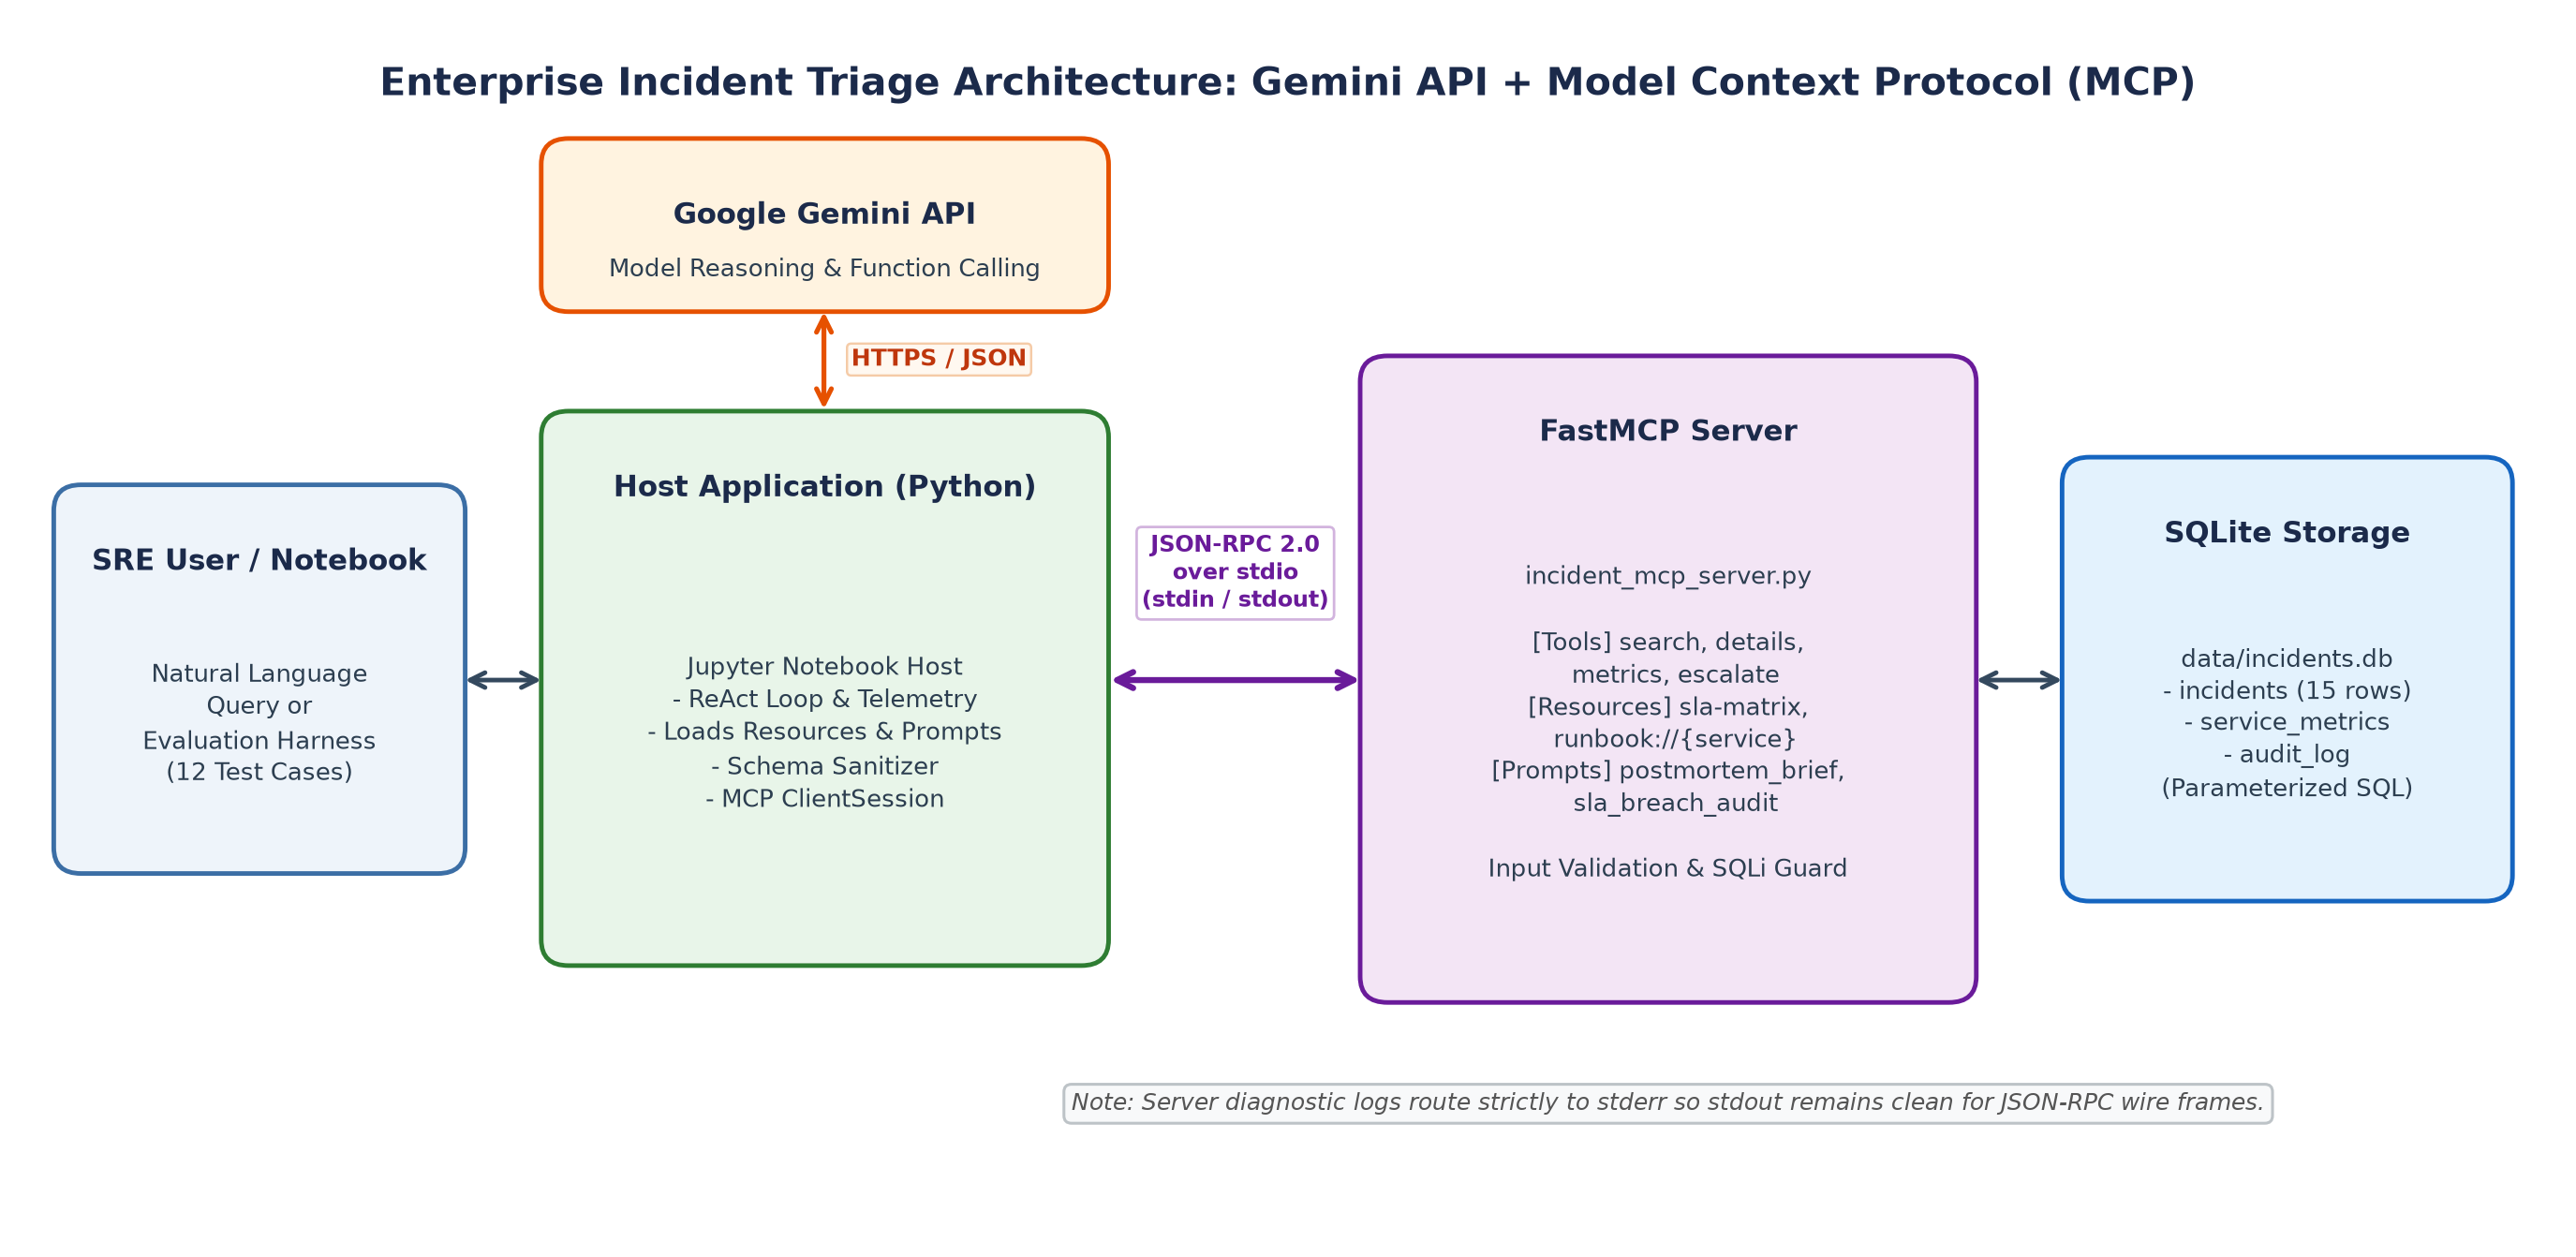


--- sequence_diagram.png ---


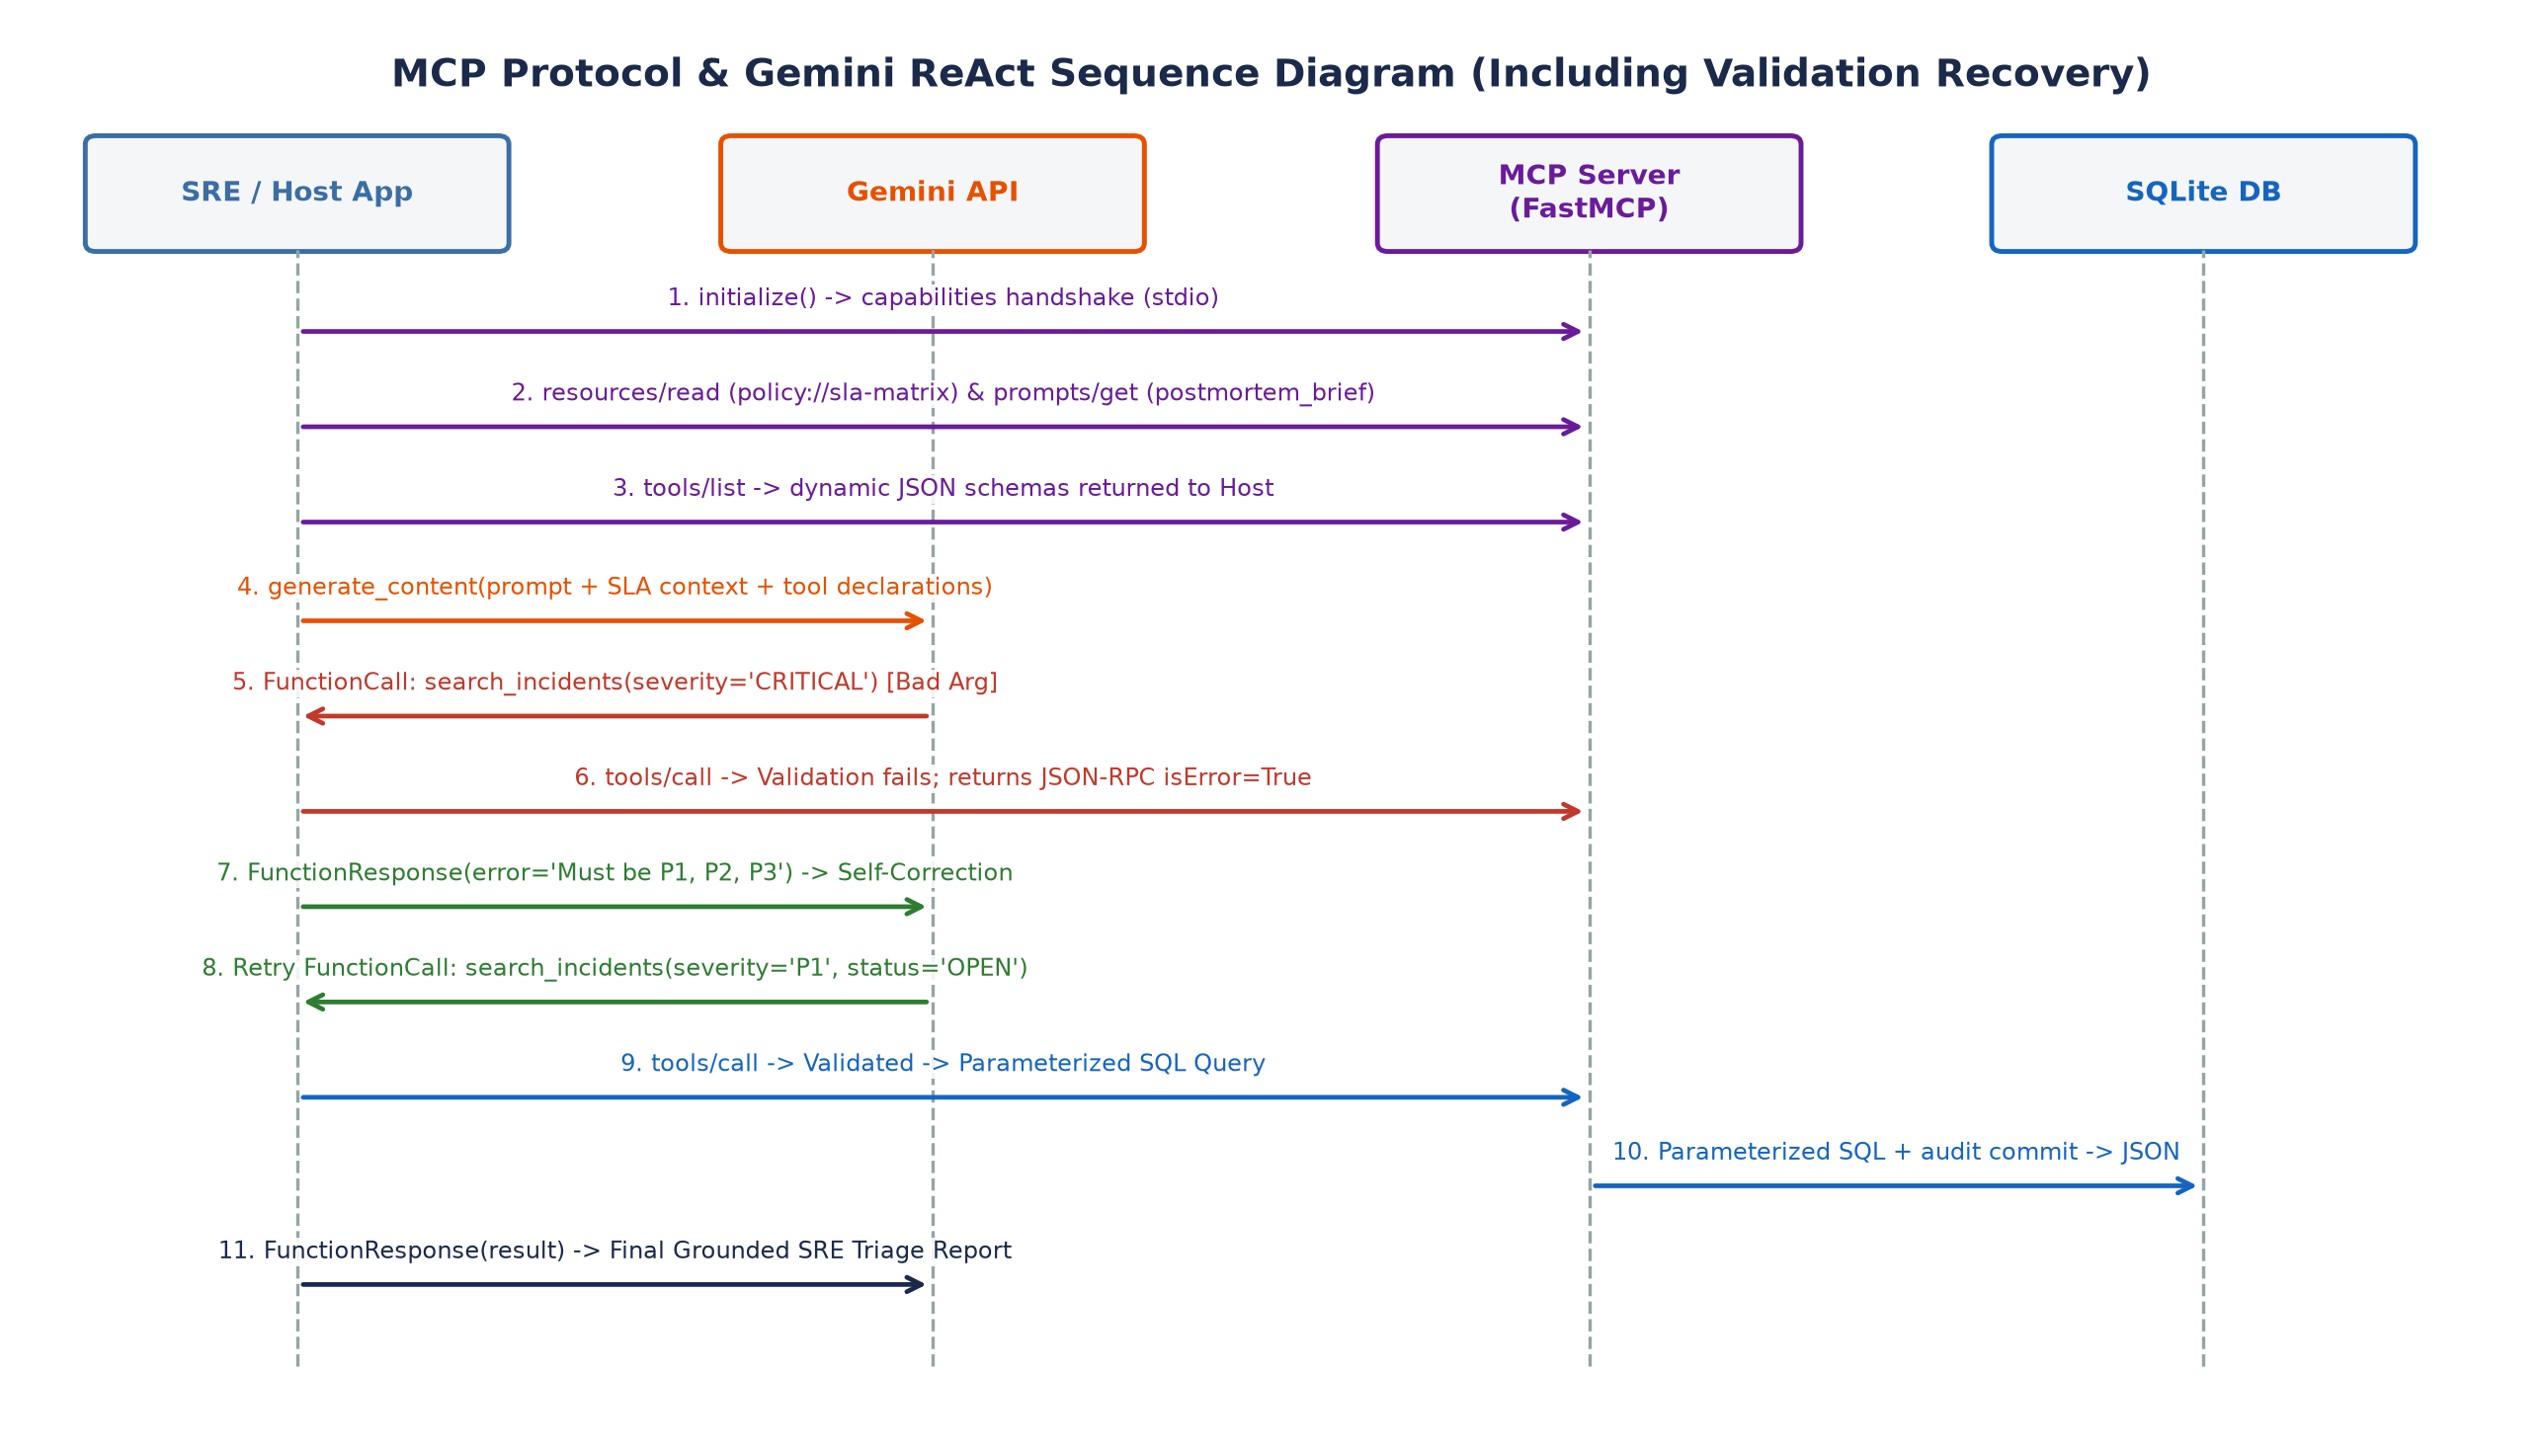


--- latency_breakdown.png ---


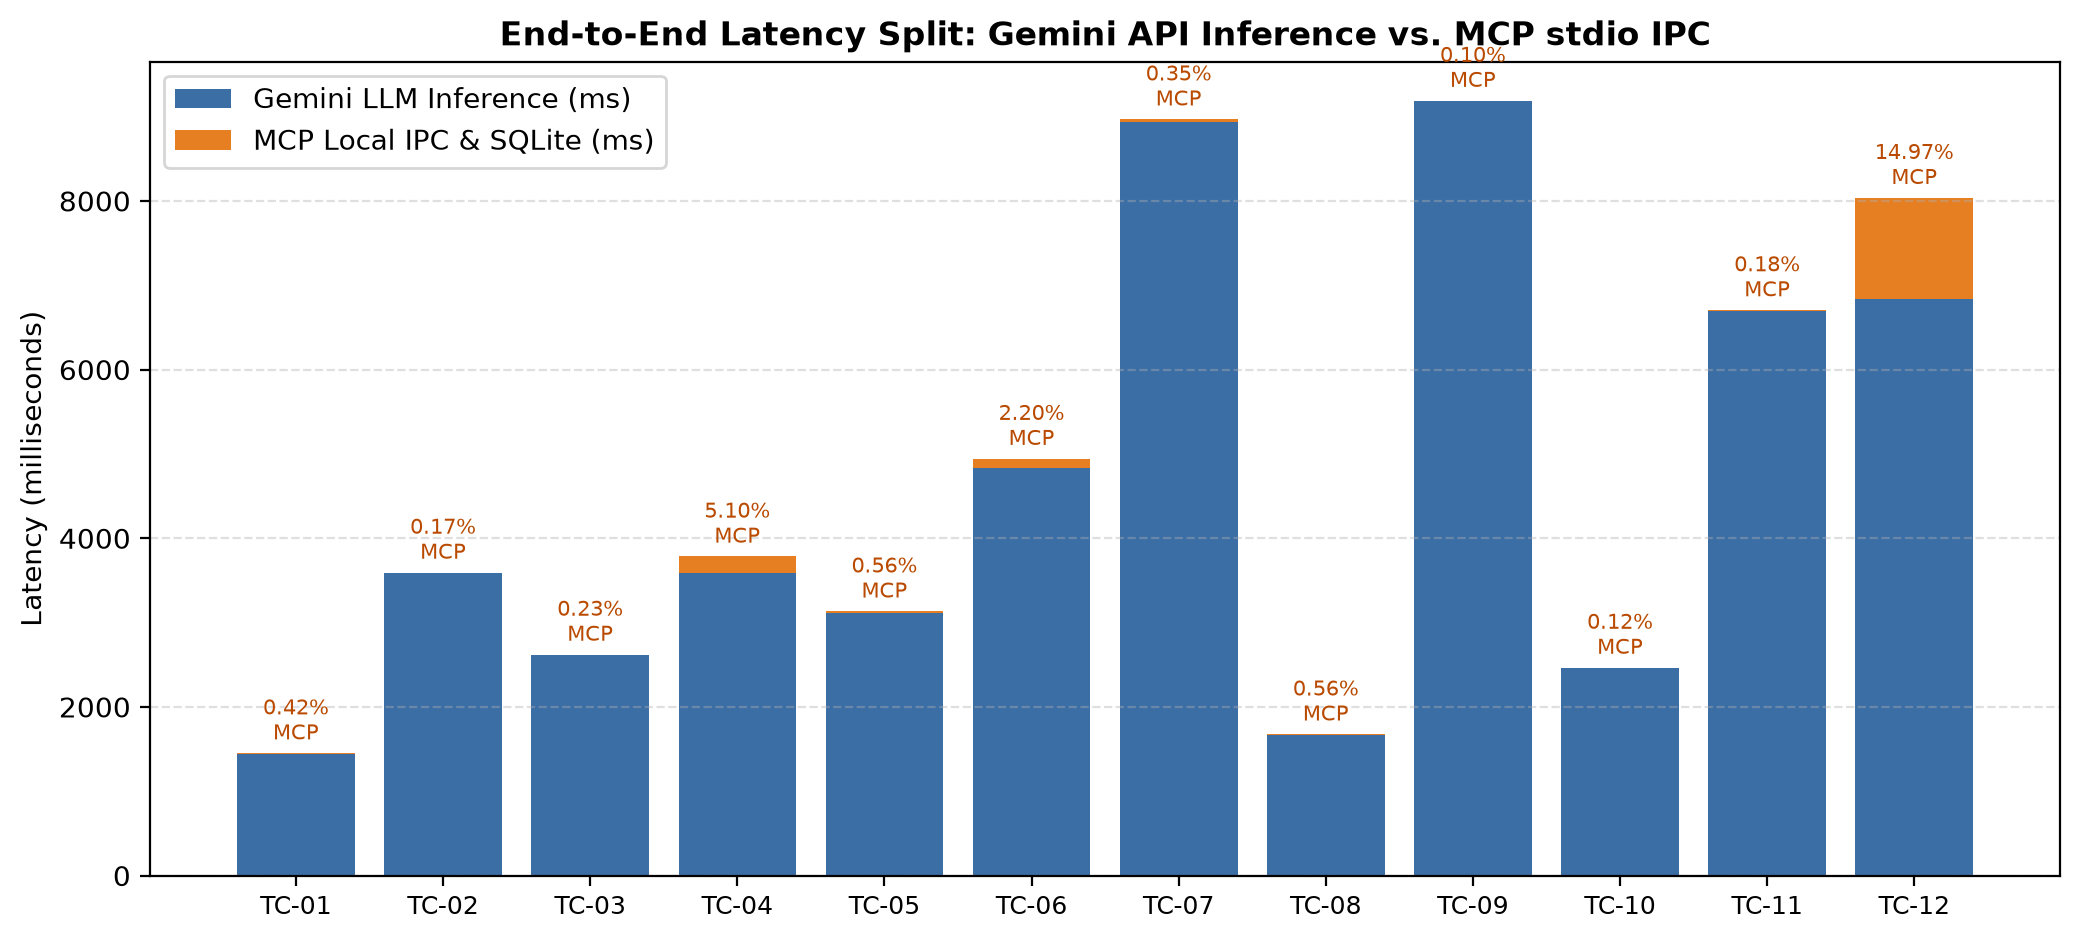


--- outcomes_by_category.png ---


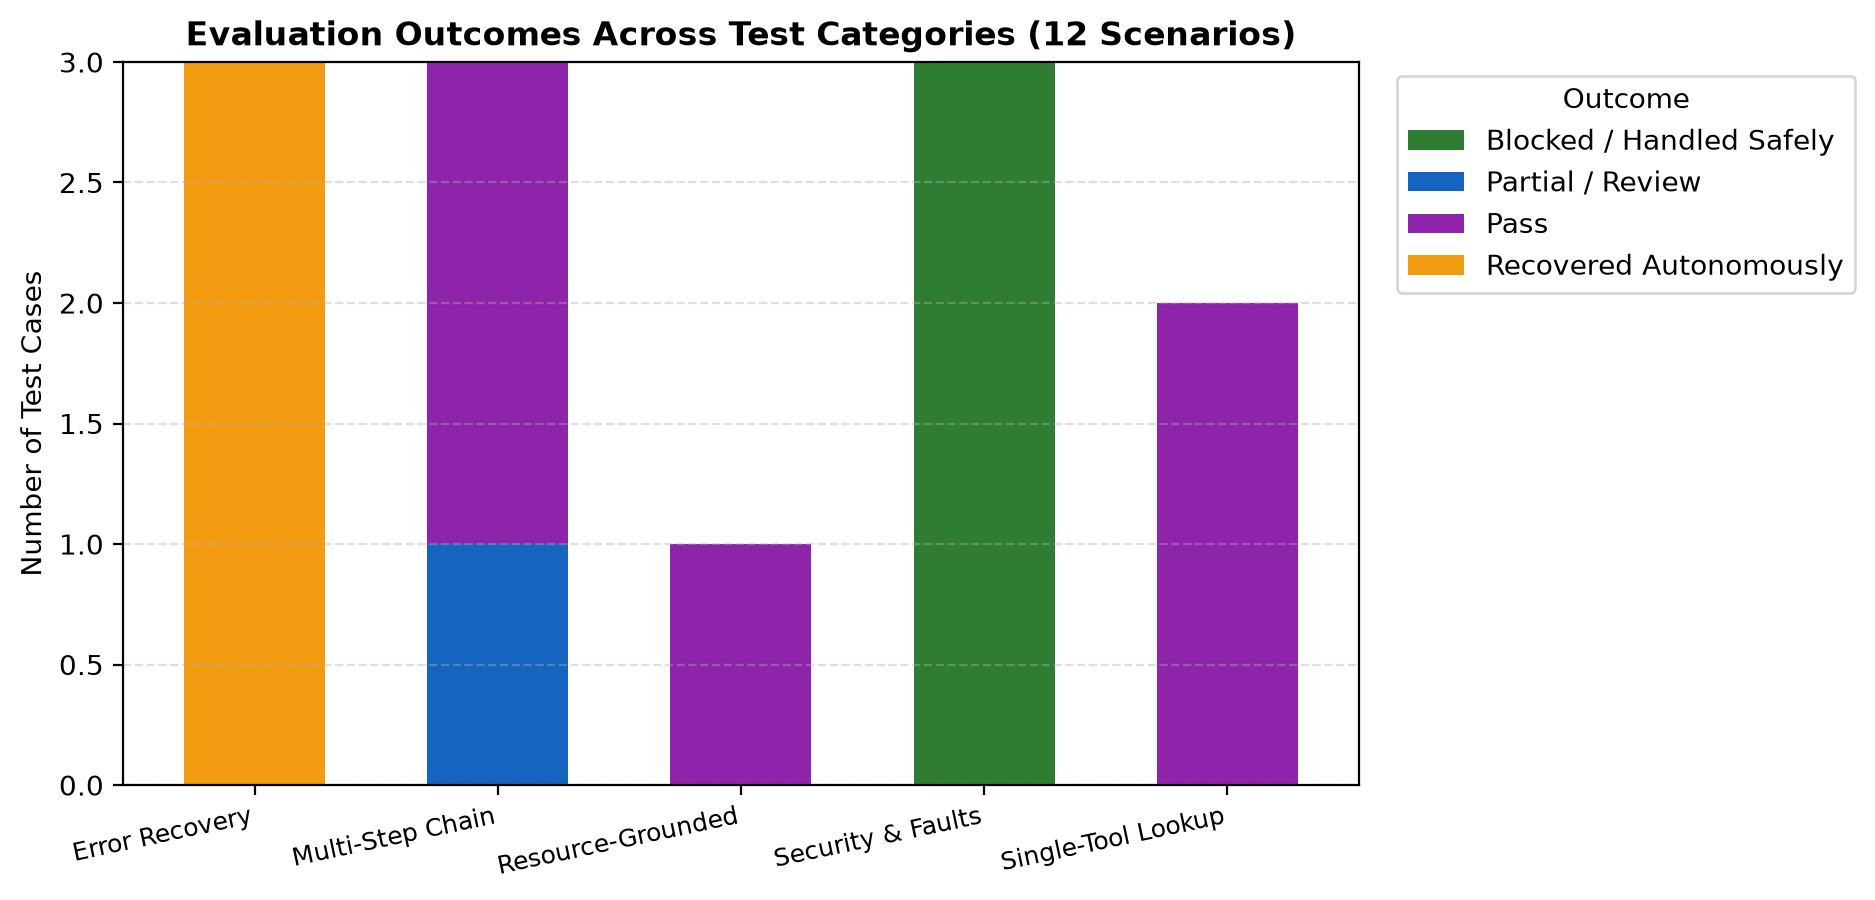


--- token_usage.png ---


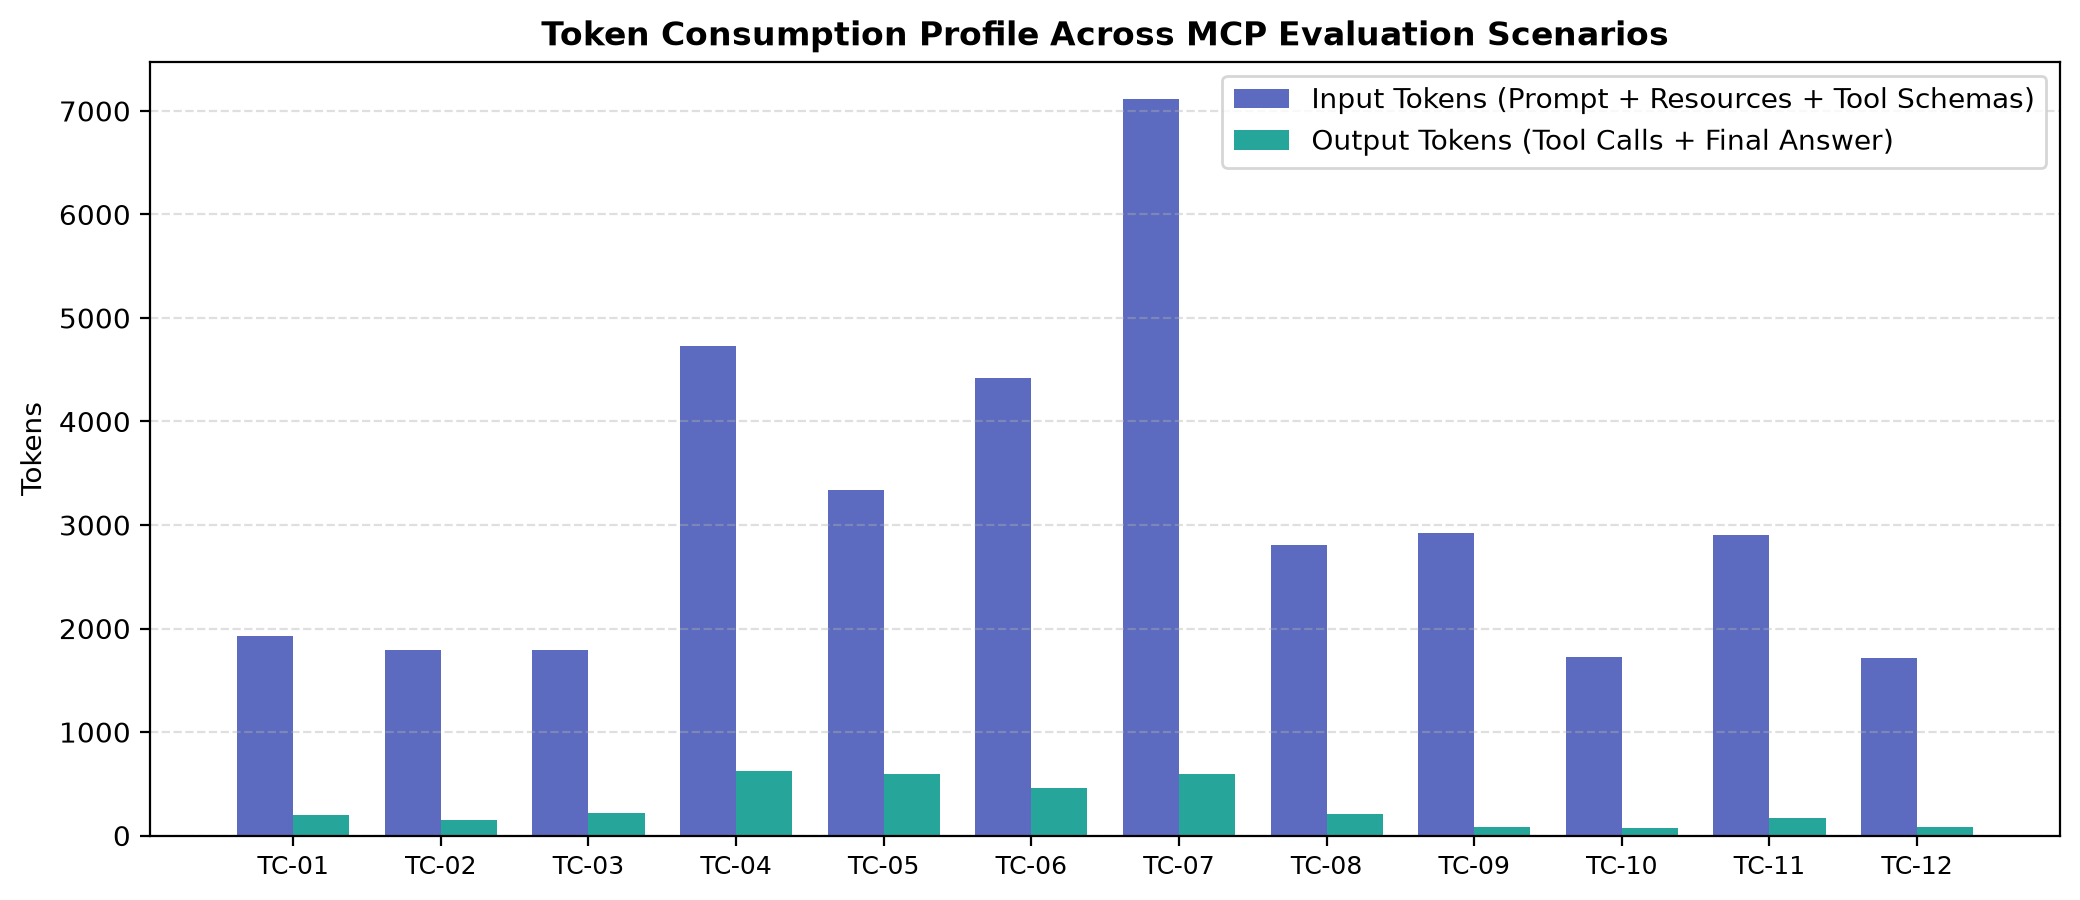

In [15]:
from IPython.display import Image, display
import matplotlib
matplotlib.use("Agg")
import matplotlib.patches as patches
import matplotlib.pyplot as plt


def draw_architecture_diagram(out_path: Path) -> None:
    fig, ax = plt.subplots(figsize=(12.6, 6.2), dpi=220)
    ax.set_xlim(0, 13.0)
    ax.set_ylim(0, 6.6)
    ax.axis("off")

    ax.text(
        6.5, 6.25,
        "Enterprise Incident Triage Architecture: Gemini API + Model Context Protocol (MCP)",
        ha="center", va="center", fontsize=13.5, fontweight="bold", color="#1B2A4A",
    )

    def box(x, y, w, h, title, body, facecolor, edgecolor):
        rect = patches.FancyBboxPatch(
            (x, y), w, h, boxstyle="round,pad=0.08,rounding_size=0.14",
            linewidth=1.6, edgecolor=edgecolor, facecolor=facecolor,
        )
        ax.add_patch(rect)
        ax.text(x + w / 2, y + h - 0.34, title, ha="center", va="center", fontsize=10, fontweight="bold", color="#1B2A4A")
        ax.text(x + w / 2, y + (h - 0.48) / 2, body, ha="center", va="center", fontsize=8.4, color="#2C3E50", linespacing=1.35)

    box(0.25, 2.05, 1.95, 1.95, "SRE User / Notebook", "Natural Language\nQuery or\nEvaluation Harness\n(12 Test Cases)", "#EEF4FA", "#3B6EA5")
    box(2.75, 1.55, 2.75, 2.85, "Host Application (Python)", "Jupyter Notebook Host\n- ReAct Loop & Telemetry\n- Loads Resources & Prompts\n- Schema Sanitizer\n- MCP ClientSession", "#E8F5E9", "#2E7D32")
    box(2.75, 5.10, 2.75, 0.78, "Google Gemini API", "Model Reasoning & Function Calling", "#FFF3E0", "#E65100")
    box(6.95, 1.35, 3.00, 3.35, "FastMCP Server", "incident_mcp_server.py\n\n[Tools] search, details,\n  metrics, escalate\n[Resources] sla-matrix,\n  runbook://{service}\n[Prompts] postmortem_brief,\n  sla_breach_audit\n\nInput Validation & SQLi Guard", "#F3E5F5", "#6A1B9A")
    box(10.55, 1.90, 2.15, 2.25, "SQLite Storage", "data/incidents.db\n- incidents (15 rows)\n- service_metrics\n- audit_log\n(Parameterized SQL)", "#E3F2FD", "#1565C0")

    arrow_kw = dict(arrowstyle="<->", lw=1.6, color="#34495E", mutation_scale=13)
    ax.annotate("", xy=(2.70, 3.02), xytext=(2.25, 3.02), arrowprops=arrow_kw)
    ax.annotate("", xy=(4.12, 5.05), xytext=(4.12, 4.46), arrowprops=dict(arrowstyle="<->", lw=1.7, color="#E65100", mutation_scale=13))
    ax.text(4.26, 4.76, "HTTPS / JSON", fontsize=8.2, fontweight="bold", color="#BF360C", va="center",
            bbox=dict(boxstyle="round,pad=0.18", facecolor="#FFF8F0", edgecolor="#F5CBA7", lw=0.8))
    ax.annotate("", xy=(6.90, 3.02), xytext=(5.56, 3.02), arrowprops=dict(arrowstyle="<->", lw=2.1, color="#6A1B9A", mutation_scale=14))
    ax.text(6.23, 3.60, "JSON-RPC 2.0\nover stdio\n(stdin / stdout)", ha="center", va="center",
            fontsize=8.0, fontweight="bold", color="#6A1B9A",
            bbox=dict(boxstyle="round,pad=0.22", facecolor="#FFFFFF", edgecolor="#D2B4DE", lw=0.9))
    ax.annotate("", xy=(10.50, 3.02), xytext=(10.00, 3.02), arrowprops=arrow_kw)
    ax.text(8.45, 0.72, "Note: Server diagnostic logs route strictly to stderr so stdout remains clean for JSON-RPC wire frames.",
            ha="center", va="center", fontsize=8.3, style="italic", color="#555555",
            bbox=dict(boxstyle="round,pad=0.32", facecolor="#F8F9FA", edgecolor="#BDC3C7"))

    plt.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    plt.close(fig)


def draw_sequence_diagram(out_path: Path) -> None:
    fig, ax = plt.subplots(figsize=(11.8, 6.8), dpi=220)
    ax.set_xlim(0, 11.8)
    ax.set_ylim(0, 8.3)
    ax.axis("off")
    ax.text(5.9, 7.98, "MCP Protocol & Gemini ReAct Sequence Diagram (Including Validation Recovery)",
            ha="center", va="center", fontsize=12.8, fontweight="bold", color="#1B2A4A")

    actors = [
        (1.3, "SRE / Host App", "#3B6EA5"),
        (4.3, "Gemini API", "#E65100"),
        (7.4, "MCP Server\n(FastMCP)", "#6A1B9A"),
        (10.3, "SQLite DB", "#1565C0"),
    ]
    for x, label, color in actors:
        rect = patches.FancyBboxPatch((x - 0.95, 7.00), 1.9, 0.58, boxstyle="round,pad=0.05",
                                      facecolor="#F4F6F8", edgecolor=color, linewidth=1.6)
        ax.add_patch(rect)
        ax.text(x, 7.29, label, ha="center", va="center", fontsize=9.2, fontweight="bold", color=color)
        ax.plot([x, x], [0.4, 6.96], linestyle="--", color="#95A5A6", linewidth=1.1)

    steps = [
        (6.48, 1.3, 7.4, "1. initialize() -> capabilities handshake (stdio)", "#6A1B9A"),
        (5.92, 1.3, 7.4, "2. resources/read (policy://sla-matrix) & prompts/get (postmortem_brief)", "#6A1B9A"),
        (5.36, 1.3, 7.4, "3. tools/list -> dynamic JSON schemas returned to Host", "#6A1B9A"),
        (4.78, 1.3, 4.3, "4. generate_content(prompt + SLA context + tool declarations)", "#E65100"),
        (4.22, 4.3, 1.3, "5. FunctionCall: search_incidents(severity='CRITICAL') [Bad Arg]", "#C0392B"),
        (3.66, 1.3, 7.4, "6. tools/call -> Validation fails; returns JSON-RPC isError=True", "#C0392B"),
        (3.10, 1.3, 4.3, "7. FunctionResponse(error='Must be P1, P2, P3') -> Self-Correction", "#2E7D32"),
        (2.54, 4.3, 1.3, "8. Retry FunctionCall: search_incidents(severity='P1', status='OPEN')", "#2E7D32"),
        (1.98, 1.3, 7.4, "9. tools/call -> Validated -> Parameterized SQL Query", "#1565C0"),
        (1.46, 7.4, 10.3, "10. Parameterized SQL + audit commit -> JSON", "#1565C0"),
        (0.88, 1.3, 4.3, "11. FunctionResponse(result) -> Final Grounded SRE Triage Report", "#1B2A4A"),
    ]
    for y, x1, x2, text, color in steps:
        ax.annotate("", xy=(x2, y), xytext=(x1, y), arrowprops=dict(arrowstyle="->", lw=1.55, color=color, mutation_scale=12))
        ax.text((x1 + x2) / 2, y + 0.12, text, ha="center", va="bottom", fontsize=8.0, color=color, fontweight="medium",
                bbox=dict(boxstyle="square,pad=0.08", facecolor="white", edgecolor="none", alpha=0.88))

    plt.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    plt.close(fig)


def draw_experiment_charts(csv_path: Path) -> list[Path]:
    df = pd.read_csv(csv_path)
    saved = []

    fig, ax = plt.subplots(figsize=(10.5, 4.8), dpi=200)
    x = range(len(df))
    ax.bar(x, df["llm_ms"], label="Gemini LLM Inference (ms)", color="#3B6EA5")
    ax.bar(x, df["mcp_ms"], bottom=df["llm_ms"], label="MCP Local IPC & SQLite (ms)", color="#E67E22")
    ax.set_xticks(list(x))
    ax.set_xticklabels(df["test_id"], fontsize=9)
    ax.set_ylabel("Latency (milliseconds)")
    ax.set_title("End-to-End Latency Split: Gemini API Inference vs. MCP stdio IPC", fontsize=12, fontweight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend(frameon=True)
    for idx, row in df.iterrows():
        ax.text(idx, row["llm_ms"] + row["mcp_ms"] + 80, f"{row['mcp_overhead_pct']:.2f}%\nMCP", ha="center", va="bottom", fontsize=7.5, color="#B94A00")
    p1 = CHARTS_DIR / "latency_breakdown.png"
    plt.tight_layout()
    fig.savefig(p1, bbox_inches="tight")
    plt.close(fig)
    saved.append(p1)

    ct = pd.crosstab(df["category"], df["outcome"])
    fig, ax = plt.subplots(figsize=(9.5, 4.6), dpi=200)
    palette = ["#2E7D32", "#1565C0", "#8E24AA", "#F39C12", "#C0392B"]
    ct.plot(kind="bar", stacked=True, ax=ax, color=palette[: len(ct.columns)], width=0.58)
    ax.set_title("Evaluation Outcomes Across Test Categories (12 Scenarios)", fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Number of Test Cases")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=12, ha="right", fontsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
    p2 = CHARTS_DIR / "outcomes_by_category.png"
    plt.tight_layout()
    fig.savefig(p2, bbox_inches="tight")
    plt.close(fig)
    saved.append(p2)

    fig, ax = plt.subplots(figsize=(10.5, 4.6), dpi=200)
    width = 0.38
    idx_list = list(range(len(df)))
    ax.bar([i - width / 2 for i in idx_list], df["input_tokens"], width=width, label="Input Tokens (Prompt + Resources + Tool Schemas)", color="#5C6BC0")
    ax.bar([i + width / 2 for i in idx_list], df["output_tokens"], width=width, label="Output Tokens (Tool Calls + Final Answer)", color="#26A69A")
    ax.set_xticks(idx_list)
    ax.set_xticklabels(df["test_id"], fontsize=9)
    ax.set_ylabel("Tokens")
    ax.set_title("Token Consumption Profile Across MCP Evaluation Scenarios", fontsize=12, fontweight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend(frameon=True)
    p3 = CHARTS_DIR / "token_usage.png"
    plt.tight_layout()
    fig.savefig(p3, bbox_inches="tight")
    plt.close(fig)
    saved.append(p3)

    return saved


arch_p = CHARTS_DIR / "architecture_diagram.png"
seq_p = CHARTS_DIR / "sequence_diagram.png"
draw_architecture_diagram(arch_p)
draw_sequence_diagram(seq_p)

figs_to_show = [arch_p, seq_p]
csv_file = OUTPUT_DIR / "experiment_results.csv"
if csv_file.exists():
    figs_to_show.extend(draw_experiment_charts(csv_file))
else:
    print("[INFO] Run Section 9 first to also generate latency, outcome, and token charts.")

for fig_path in figs_to_show:
    print(f"\n--- {fig_path.name} ---")
    display(Image(filename=str(fig_path), width=820))